# Feature Importance Analyses for Mislocalized Variants

We select for the interpretable CellProfiler features that contribute most significantly in the XGBoost Classifier to help distinguish the mislocalized variants from their respective reference alleles.

In [147]:
import os
import polars as pl
import seaborn as sns
from adjustText import adjust_text
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
from functools import reduce
import operator
from adjustText import adjust_text

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

# controls = {
#     "TC": ["EGFP"],
#     "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
#     "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
#     # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
#     # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
#     # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
#     # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
# }

# ctrl_alleles = [k_v for k_v in controls.values()]
# ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# # ctrl_alleles_flat

np.random.seed(42)
random.seed(42)

## 1. Load feature importance and classifier info

### 1.1 Feature importance for each mislocalized variant

In [155]:
## classification results in SM pipeline
SM_CLASS_RES_DIR = CLASS_RESULTS_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells"
FEAT = "GFP"
MISLOCALIZED_LABEL = "Altered_95th_perc_any_batches_GFP"

In [19]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col(MISLOCALIZED_LABEL)==1
)
allele_list = list(imaging_summary_clinvar_hits["gene_allele"]) + list(imaging_summary_clinvar_hits["Gene"].unique())
bio_reps = list(imaging_summary_clinvar_hits["Metadata_Bio_Batch"].unique())

In [73]:
feat_import_df_feat = pl.DataFrame()
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    for batch_id in bio_rep_batches:
        # Read the data
        feat_df = pl.scan_csv(f"{SM_CLASS_RES_DIR.format(batch_id=batch_id)}/feat_importance.csv")
        meta_cols = [c for c in feat_df.collect_schema().names() if c.startswith("Metadata_") or c.startswith("Group") or c == "Batch"]
        feat_cols = [c for c in feat_df.collect_schema().names() if c not in meta_cols and FEAT in c]
        # print(feat_cols)
        feat_df_batch = feat_df.with_columns(
            [pl.col(c).cast(pl.Float64, strict=False).alias(c) for c in feat_cols]
        ).with_columns(
            pl.lit(batch_id).alias("Metadata_Batch"),
            pl.col("Group2").str.split('_').list.slice(-2).list.join("_").alias("Metadata_gene_allele")
       ).filter(
            (pl.col("Metadata_Feature_Type")==FEAT)&(~pl.col("Metadata_Control"))
            &(pl.col("Group1").is_in(allele_list)|(pl.col("Metadata_gene_allele").is_in(allele_list)))
        ).select(meta_cols + feat_cols + ["Metadata_Batch", "Metadata_gene_allele"])
        feat_import_df_feat = pl.concat([feat_import_df_feat, feat_df_batch.collect()], how="diagonal")

### 1.2 Select for the top 5 CP features with importance > 0.01 for each mislocalized variant

In [79]:
from tqdm import tqdm
key_alleles_df = imaging_summary_clinvar_hits.to_pandas()
feat_df = pl.DataFrame()
top_num, importance_thres = 5, 0.01

for j, allele in tqdm(key_alleles_df.iterrows()):
    batch_list = list(feat_import_df_feat.filter(pl.col("Metadata_gene_allele")==allele["gene_allele"]).unique("Metadata_Batch")["Metadata_Batch"])
    allele_df = pl.DataFrame()
    
    for i, batch in enumerate(batch_list):
        batch_df = feat_import_df_feat.filter(
            (pl.col("Metadata_Batch")==batch)&(pl.col("Metadata_gene_allele")==allele["gene_allele"])
        )
        feat_cols = [col for col in batch_df.columns if "Metadata" not in col and "Group" not in col]
        batch_df = batch_df.filter(
            ~pl.all_horizontal(pl.col(feat_cols).is_null())
        )
        non_null_gfp = [col for col in feat_cols if not batch_df[col].is_null().any()]
        batch_df_col = (
            batch_df.select(non_null_gfp).mean()
           .transpose(include_header=True)
           .filter(pl.col("column_0") > importance_thres)
           .sort("column_0", descending=True)
           .head(top_num)#["column"]
           # .to_list()
        )
        if not allele_df.is_empty():
            allele_df = allele_df.join(
                batch_df_col.with_columns(
                    pl.col("column_0").alias(batch),
                    pl.col("column").alias("index"),
                ).select("index", batch),
                on="index",
                how="full",
                coalesce=True
            )
        else:
            allele_df = batch_df_col.with_columns(
                pl.col("column_0").alias(batch),
                pl.col("column").alias("index"),
            ).select("index", batch)
            
    allele_df = allele_df.with_columns(
        pl.mean_horizontal(pl.col([col for col in allele_df.columns if "Batch" in col])).alias("feat_importance"),
        pl.col("index").alias("cp_feature")
    ).select(
        pl.col(["cp_feature", "feat_importance"])
    ).rename(
        {"feat_importance": allele["gene_allele"]}
    )
    
    if not feat_df.is_empty():
        feat_df = feat_df.join(
            allele_df,
            left_on="cp_feature",
            right_on="cp_feature",
            how="full",
            coalesce=True
        )
    else:
        feat_df = allele_df

320it [00:45,  7.06it/s]


In [82]:
# feat_df.write_csv("../../3_outputs/feat_importance_mislocalized_allele_hits.csv")

### 1.3 Load CellProfiler features

#### Loading QC info per each imaging well

In [9]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

#### Load the features from the valid cells only

In [83]:
## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

In [86]:
# Paths
ref_var_cell_qc_prof_df = pl.DataFrame()
target_gene_alleles = []
meta_cols = [
    "Metadata_CellID",
    "Metadata_gene_allele",
    "Metadata_Well",
    "Metadata_Plate",
    "Metadata_node_type"
]

# Get meta features
for bio_rep in bio_reps:
    bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                PASS_QC_PROF_PQ.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        ).collect()
        # feat_cols = [col for col in batch_alleles.columns if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) and ("GFP".lower() not in col.lower())]
        batch_alleles = batch_alleles.join(
            img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==FEAT).select(pl.col("plate", "well", "is_bg")),
            left_on=["Metadata_Plate", "Metadata_Well"],
            right_on=["plate", "well"]
        ).filter(
            ~pl.col("is_bg")
        ).select(pl.col(meta_cols))
        ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

#### Load all the features available

In [87]:
# Paths
ref_var_cell_all_prof_list = []
for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        batch_alleles = (
            pl.scan_parquet(
                ALL_PROF_QC.format(batch_id=batch_id)
            )
            .filter(pl.col("Metadata_gene_allele").is_in(allele_list))
            .with_columns(
                pl.concat_str(
                    [
                        "Metadata_Plate",
                        "Metadata_Well",
                        "Metadata_ImageNumber",
                        "Metadata_ObjectNumber",
                    ],
                    separator="_",
                ).alias("Metadata_CellID")
            )
        )
        ref_var_cell_all_prof_list.append(batch_alleles)

all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (FEAT.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
select_cols = list(all_feat_cols) + ["Metadata_CellID"]
ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])
# This method of joining ensures that only cells past filters are included in the abundance analysis
ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
                                                        on="Metadata_CellID", 
                                                        how="left", coalesce=True)

### 1.4 Aggregate the feature to batch-allele level

In [95]:
ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
    pl.col("Metadata_Plate")
      # capture a “B” followed by any non-underscore chars up to the first “A”
      .str.extract(r"(B[^_]*?A)", 1)
      .alias("Metadata_Batch")
).with_columns(
    pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
)

ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
    "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
).agg(
    pl.col(col).median().alias(col)
    for col in all_feat_cols
    if not col.startswith("Metadata_")
).group_by(
    "Metadata_gene_allele", "Metadata_Bio_Batch"
).agg(
    pl.col(col).median().alias(col)
    for col in all_feat_cols
    if not col.startswith("Metadata_")
).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"])

non_null_cols_batch = [c for c in feat_df["cp_feature"].to_list() if c in ref_var_allele_batch_all_prof_df.columns]
var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
    var_allele_meta_cols+non_null_cols_batch
)
ref_var_allele_batch_all_prof_df

Metadata_gene_allele,Metadata_Bio_Batch,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10,Nuclei_RadialDistribution_RadialCV_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_5of10,Cells_Correlation_RWC_GFP_Mito,Nuclei_Correlation_K_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cells_Correlation_Correlation_GFP_Mito,Cytoplasm_RadialDistribution_RadialCV_GFP_8of10,Cells_Intensity_MADIntensity_GFP,Cytoplasm_Correlation_Correlation_GFP_Mito,Nuclei_Correlation_Overlap_GFP_Mito,Cells_Texture_Correlation_GFP_5_00_256,Cells_Correlation_RWC_Mito_GFP,Cytoplasm_Granularity_1_GFP,Cells_Texture_InfoMeas1_GFP_10_02_256,Cytoplasm_Intensity_MaxIntensity_GFP,Cytoplasm_Texture_InverseDifferenceMoment_GFP_5_00_256,Nuclei_Granularity_4_GFP,Cytoplasm_Correlation_RWC_GFP_DNA,Nuclei_Correlation_RWC_DNA_GFP,Cells_RadialDistribution_MeanFrac_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_1of10,Cells_Correlation_Correlation_AGP_GFP,Cells_Correlation_Correlation_DNA_GFP,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Cells_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Granularity_1_GFP,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Nuclei_Correlation_K_GFP_AGP,Nuclei_Correlation_Correlation_DNA_GFP,Cells_Texture_Correlation_GFP_20_01_256,…,Nuclei_Texture_AngularSecondMoment_GFP_5_00_256,Cells_RadialDistribution_MeanFrac_GFP_2of10,Cytoplasm_RadialDistribution_RadialCV_GFP_2of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cells_Texture_Correlation_GFP_20_00_256,Cytoplasm_Granularity_3_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_6of10,Cells_Texture_InfoMeas1_GFP_10_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Nuclei_Texture_SumAverage_GFP_20_00_256,Cells_Texture_Correlation_GFP_20_03_256,Cells_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_Correlation_GFP_5_01_256,Cells_Texture_Correlation_GFP_5_02_256,Cytoplasm_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_20_01_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_Texture_InfoMeas2_GFP_20_02_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_00_256,Cytoplasm_Texture_InfoMeas1_GFP_20_03_256,Cytoplasm_Texture_Entropy_GFP_10_01_256,Cytoplasm_Texture_Entropy_GFP_10_00_256,Cells_Correlation_RWC_AGP_GFP,Cells_Texture_InfoMeas1_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_20_02_256,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_20_01_256,Cells_Granularity_4_GFP,Cytoplasm_Texture_InfoMeas1_GFP_20_02_256,Cells_Texture_InfoMeas1_GFP_20_03_256,Cells_Texture_Correlation_GFP_5_01_256,Nuclei_Texture_Correlation_GFP_5_03_256,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cells_Texture_InfoMeas1_GFP_20_01_256,Cytoplasm_Texture_InfoMeas1_GFP_20_01_256
str,str,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,…,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""NT5C3A_Gly202Arg""","""B16A""",0.976068,2.209367,-0.716503,1.173072,1.192465,0.771651,0.176122,-0.785894,1.272803,2.323934,1.823339,0.064702,2.254731,0.742358,-0.033019,0.2393,-0.11489,-0.086946,0.193477,-0.393849,0.857459,-0.54341,-0.267042,0.523166,0.015209,-0.303303,-0.4496,0.635494,0.269636,-0.039642,-0.852177,-0.174168,0.17037,-1.247851,-0.545782,…,0.46793,0.288213,2.537152,0.269288,-0.155404,4.521006,0.185844,-0.038065,2.153649,0.098927,-0.598233,-0.04124,0.248262,0.312586,0.211411,-0.059491,0.270633,-0.717581,-0.568877,0.473411,-0.11723,-0.514525,0.542298,0.527832,-0.686346,-0.072446,-0.097091,-0.242505,-0.119322,1.774303,-0.434775,-0.165741,-0.096142,-0.145851,0.284069,-0.105698,-0.512027
"""KCNJ2_Gly300

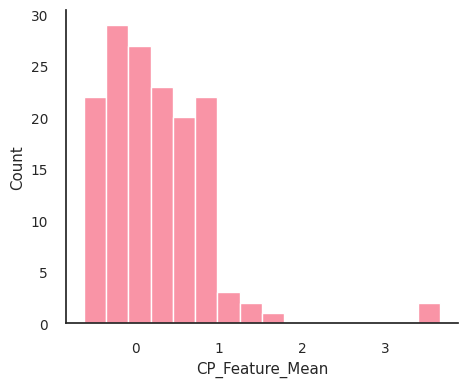

In [153]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [154]:
ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/mislocalized_variants_key_cp_features.csv")

### 1.5 Process the CP feature by INT and remove correlated features

In [131]:
from utils import *

## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)
## remove corr features
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df, corr_thres=0.9)

In [122]:
feat_df_de_corr = feat_df.filter(
    pl.col("cp_feature").is_in([c for c in ref_var_allele_batch_proc_prof_df.columns if FEAT in c])
).fill_null(0)

feat_df_de_corr.mean()

cp_feature,MLH1_Ala29Gly,GFAP_Leu352Pro,SFTPC_Leu188Gln,LITAF_Ala129Val,PMP22_Leu80Pro,COQ8A_Gly272Asp,KCTD1_Ala30Glu,LIG4_Thr9Ile,PMP22_Cys109Arg,IL10_Phe129Tyr,KCNJ2_Arg260Pro,KCNJ2_Thr139Ile,PNPO_Arg95His,MLH1_Cys680Arg,TTPA_Gly246Arg,COMP_Asp271His,KCNJ2_Arg325Cys,DCX_Pro191Arg,AGXT_Gly161Arg,GFAP_Lys279Glu,KCNJ2_Val93Ile,SMAD3_Glu239Lys,MLH1_Val185Gly,SMARCB1_Pro48Leu,GFAP_Glu371Val,CCBE1_Gly136Arg,AP2S1_Arg15Cys,AIPL1_Arg302Leu,PMP22_Leu16Pro,GFAP_Leu357Pro,SFTPA2_Gly231Val,HPRT1_Arg45Lys,SMAD1_Val3Ala,MVK_Leu265Pro,MVK_Asn301Thr,KCNJ2_Trp322Cys,…,RHO_Arg135Trp,F9_Cys170Tyr,RAD51D_Phe305Leu,BRCA1_Met548Ile,BRCA1_Ser186Tyr,ZC4H2_Ala162Thr,SHOC2_Ser2Gly,CTCF_Arg567Trp,BRCA1_Glu455Lys,LMNA_Arg41His,KRAS_Ile36Met,RHO_Cys110Tyr,ZC4H2_Ile7Val,LMNA_Arg386Thr,F9_Cys335Tyr,BRCA1_Glu116Lys,ZC4H2_Val63Leu,BRCA1_His41Arg,RAD51D_Asn138His,RAD51D_Glu233Gly,ZC4H2_Arg18Lys,ZC4H2_Ala200Thr,BRCA1_Ala102Gly,FH_Asn340Lys,LMNA_Arg377Leu,RET_Arg330Gln,RAD51D_Val132Ile,F9_Trp453Arg,BRIP1_Thr266Lys,KRAS_Gly12Asp,RAD51D_Ile17Val,RAD51D_Arg165Gln,KRAS_Gly12Val,BRCA1_Met1Ile,ZC4H2_Ala157Thr,RHO_Asp190Gly,RAD51D_His23Arg
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
null,0.00344,0.002378,0.00907,0.003119,0.009266,0.001735,0.003331,0.004629,0.011043,0.003088,0.002103,0.004992,0.008797,0.001355,0.004186,0.000896,0.002575,0.002688,0.001392,0.000616,0.001071,0.001345,0.007367,0.009597,0.001364,0.000999,0.002039,0.003304,0.006297,0.008012,0.001401,0.010685,0.006104,0.006913,0.001901,0.002316,…,0.002522,0.00148,0.001034,0.001173,0.003006,0.001947,0.001646,0.00377,0.00364,0.002101,0.00167,0.001103,0.001254,0.002148,0.000471,0.002125,0.001173,0.000378,0.001125,0.002675,0.002453,0.00154,0.003516,0.00398,0.004012,0.001341,0.001195,0.001444,0.005084,0.002093,0.001143,0.002514,0.000634,0.003777,0.002119,0.000362,0.001621


In [124]:
# feat_df_de_corr.write_csv("../../3_outputs/de_corr_feat_importance_mislocalized_allele_hits.csv")

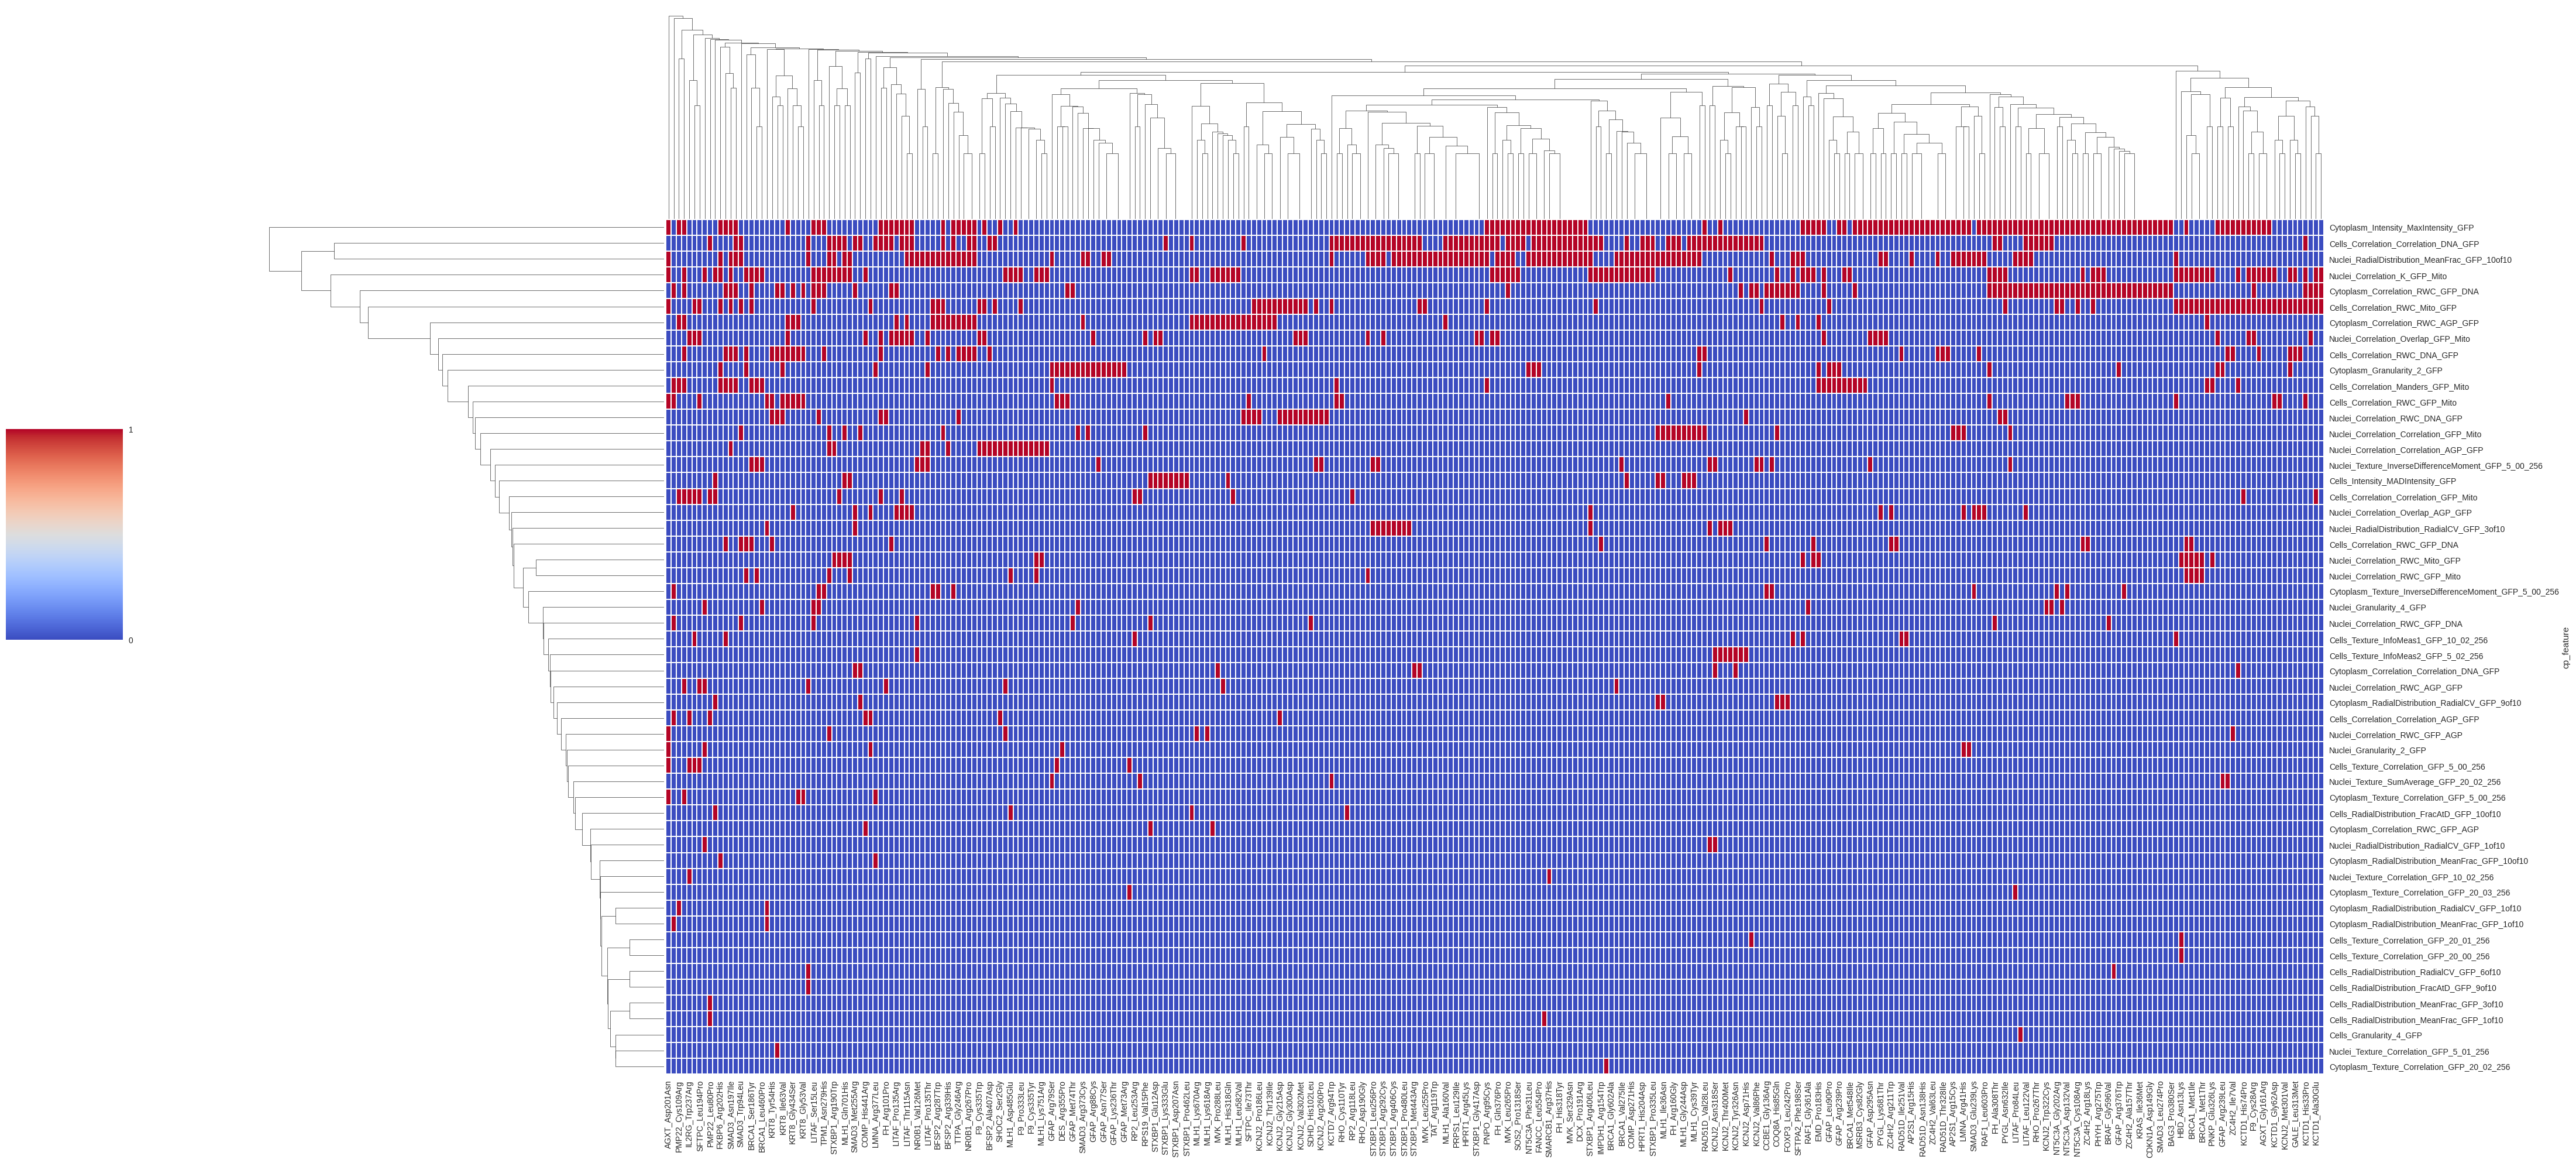

In [120]:
sns.clustermap(
    data=feat_df_de_corr.with_columns(
        pl.col([c for c in feat_df.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
    ).to_pandas().set_index("cp_feature"),
    figsize=(40, 20),
    cmap="coolwarm",
    # square=True,
    # ax=ax,
    linewidths=0.2,         # <-- width of the cell borders
    linecolor='white',       # <-- color of the borders
    col_cluster=True,
    cbar_pos=(-0.1, 0.45, 0.05, 0.18),
    cbar_kws={
        "ticks": [0, 1],        # ← only show 0 and 1
        "format": "%d",         # integer formatting
    }
)

In [143]:
feat_df_de_corr.with_columns(
    pl.col([c for c in feat_df.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
).to_pandas().set_index("cp_feature").T

cp_feature,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10,Cells_Correlation_RWC_GFP_Mito,Nuclei_Correlation_K_GFP_Mito,Cells_RadialDistribution_FracAtD_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cells_Correlation_Correlation_GFP_Mito,Cells_Intensity_MADIntensity_GFP,Nuclei_Correlation_Overlap_GFP_Mito,...,Cytoplasm_Texture_Correlation_GFP_20_03_256,Nuclei_Texture_Correlation_GFP_10_02_256,Nuclei_Correlation_RWC_GFP_Mito,Cytoplasm_Correlation_Correlation_DNA_GFP,Nuclei_Texture_Correlation_GFP_5_01_256,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cytoplasm_Texture_Correlation_GFP_20_02_256,Cells_Texture_Correlation_GFP_20_00_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cells_Granularity_4_GFP
MLH1_Ala29Gly,0,0,0,0,1,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
GFAP_Leu352Pro,1,1,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
SFTPC_Leu188Gln,0,0,0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
LITAF_Ala129Val,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
PMP22_Leu80Pro,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
KRAS_Gly12Val,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
BRCA1_Met1Ile,0,0,0,0,1,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
ZC4H2_Ala157Thr,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
RHO_Asp190Gly,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Using sample sparse binary data with shape: (320, 54)
Sparsity: 80.01% zeros

Finding optimal number of clusters for sparse binary data...
Optimizing spectral clustering...
  k=2: 2 clusters, silhouette=0.017
  k=3: 3 clusters, silhouette=0.012
  k=4: 4 clusters, silhouette=0.013
  k=5: 5 clusters, silhouette=0.011
  k=6: 6 clusters, silhouette=0.014
  k=7: 7 clusters, silhouette=0.014
  k=8: 8 clusters, silhouette=0.014
  k=9: 9 clusters, silhouette=0.016
  k=10: 10 clusters, silhouette=0.016
Computing UMAP embedding...


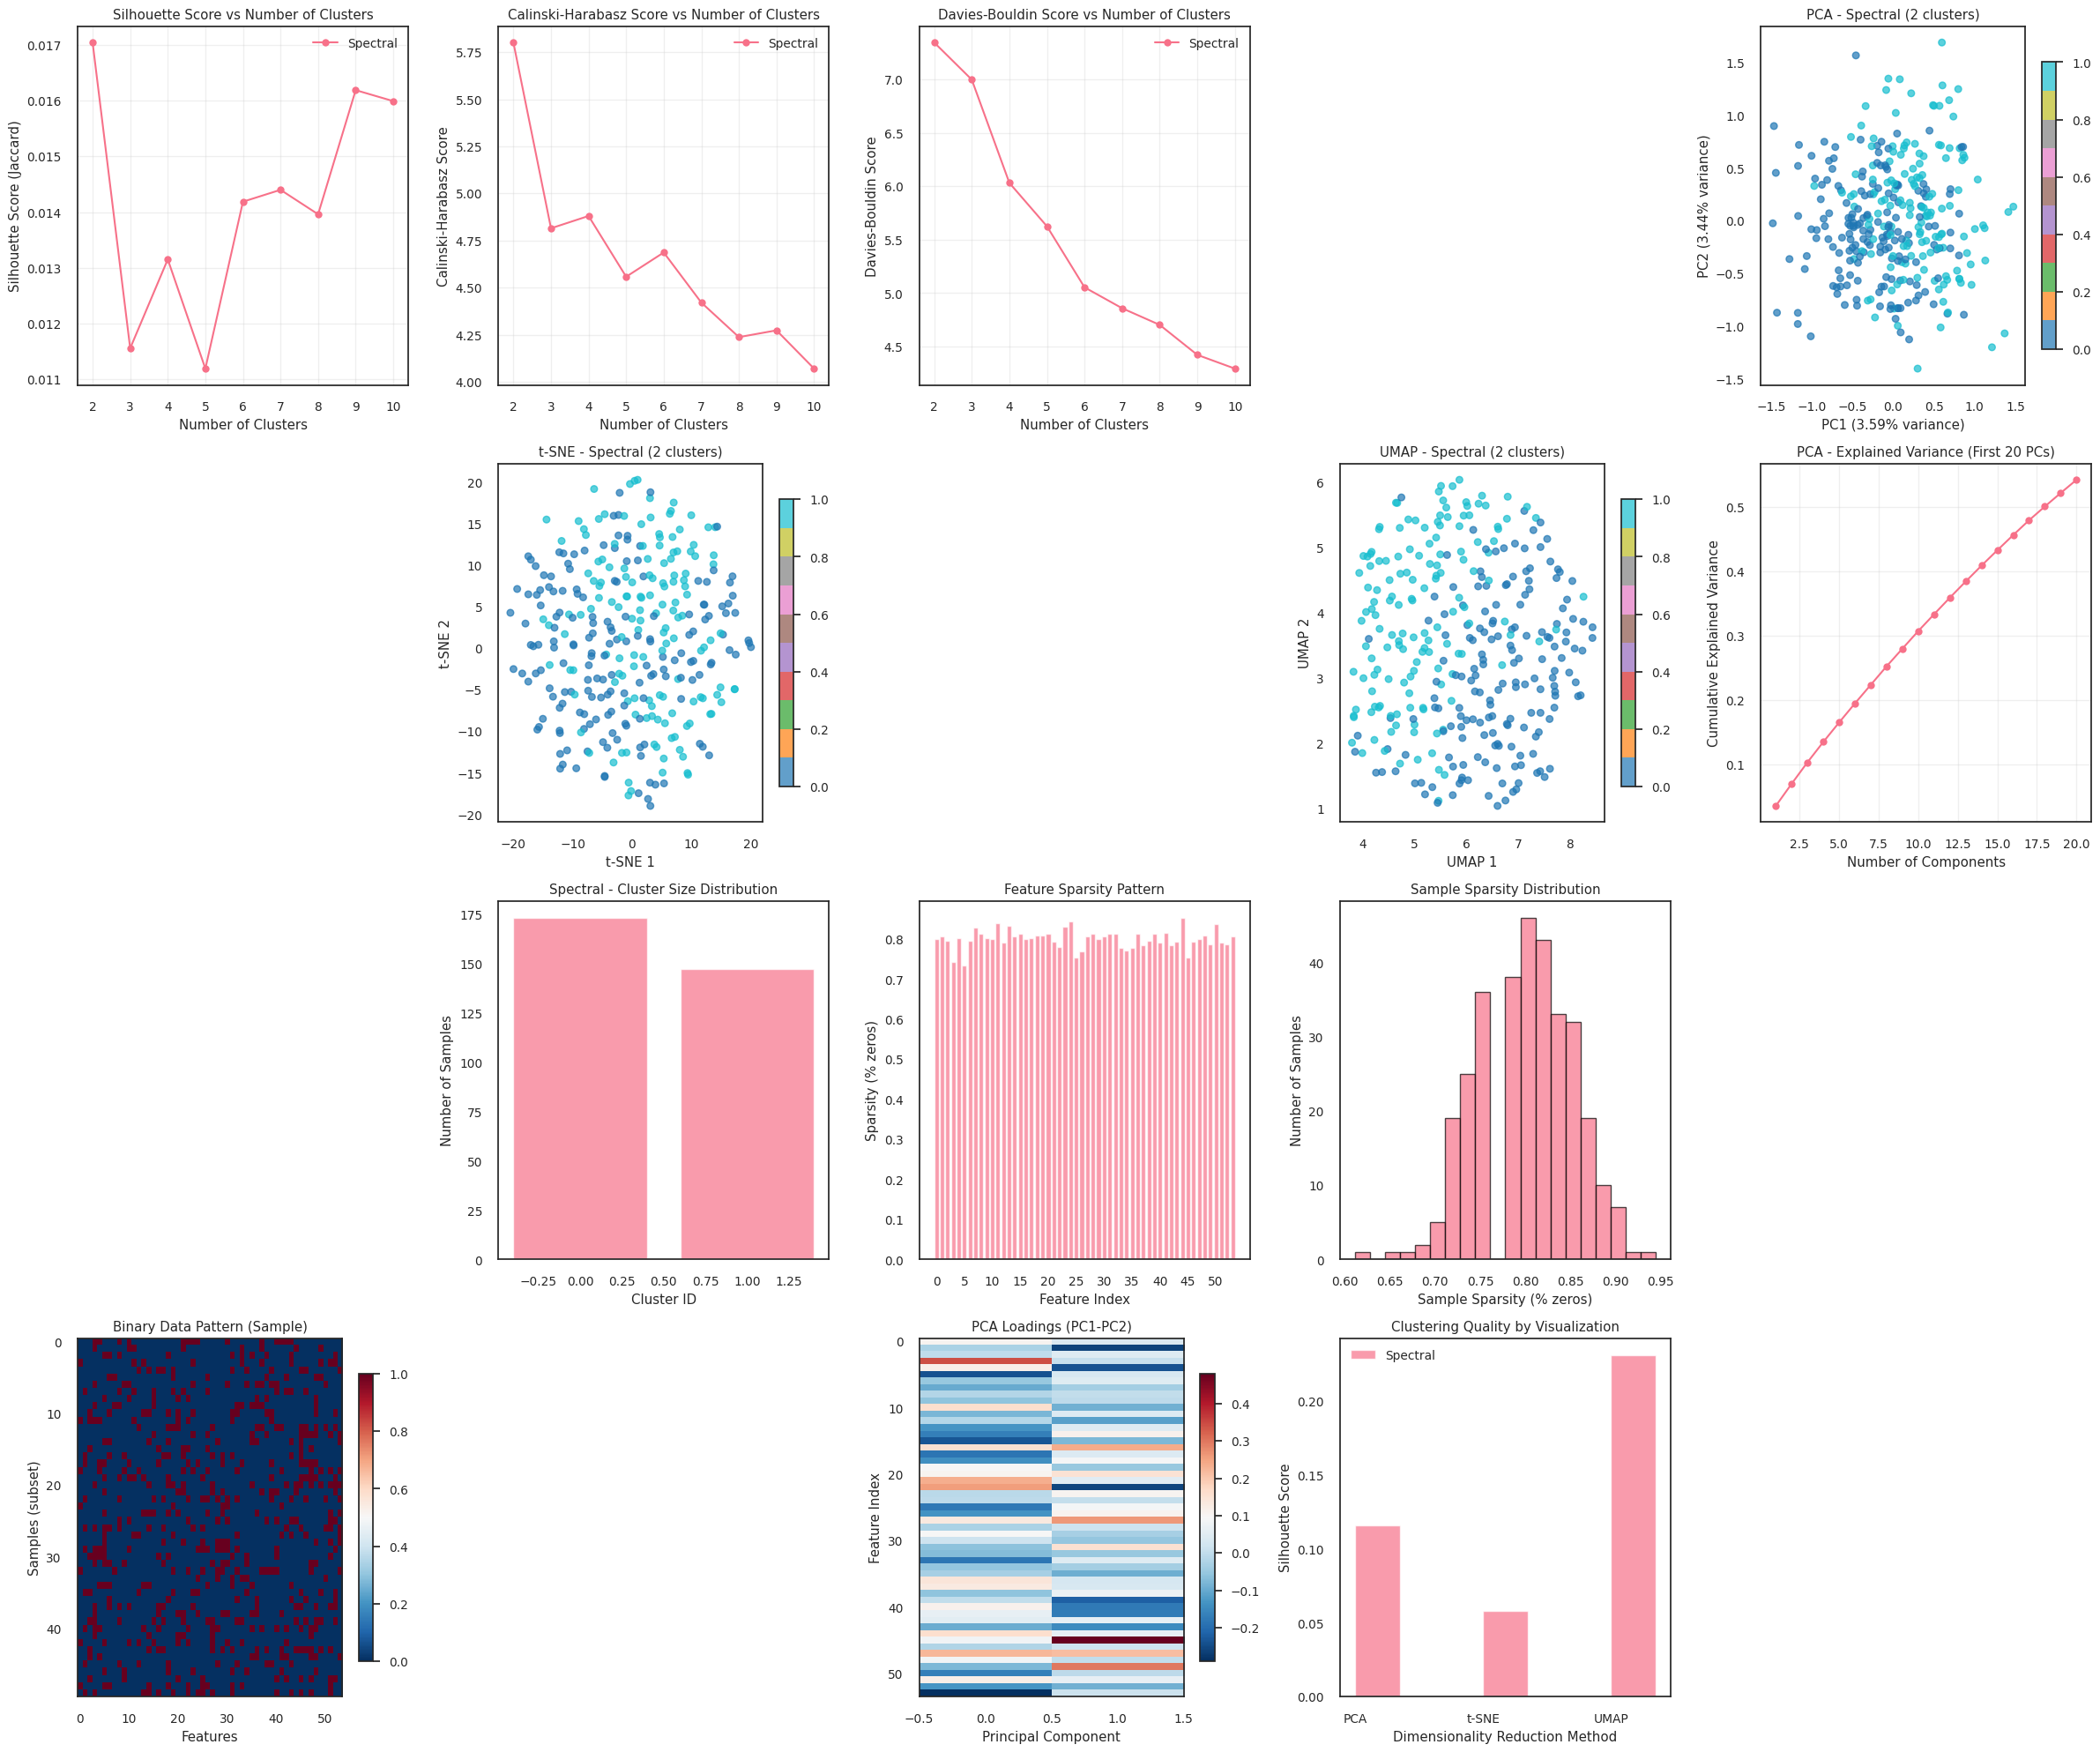


SPARSE BINARY DATA CLUSTERING RESULTS

Data characteristics:
  - Shape: (320, 54)
  - Sparsity: 80.01%
  - Density: 19.99%

Leiden Clustering:
  - Error calculating Leiden metrics: name 'leiden_labels' is not defined

Spectral Clustering:
  - Number of clusters: 2
  - Silhouette score (Jaccard): 0.017
  - Calinski-Harabasz score: 5.802
  - Davies-Bouldin score: 7.344

Cluster Agreement:

Dimensionality Reduction Quality:
  - PCA: 7.02% variance in 2D
  - t-SNE: Perplexity = 30
  - UMAP: Jaccard metric, n_neighbors = 15


In [162]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.spatial.distance import pdist, squareform, hamming, jaccard
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import SpectralClustering
from sklearn.neighbors import kneighbors_graph
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import warnings
warnings.filterwarnings('ignore')

class LeidenClustering:
    """
    Optimized Leiden clustering for sparse binary data
    """
    def __init__(self, resolution=1.0, n_iterations=10, random_state=42):
        self.resolution = resolution
        self.n_iterations = n_iterations
        self.random_state = random_state
        
    def _build_graph_sparse(self, X, n_neighbors=15, metric='jaccard'):
        """Build k-nearest neighbors graph optimized for sparse binary data"""
        # For binary data, use Jaccard distance
        if metric == 'jaccard':
            # Calculate Jaccard similarity for sparse binary matrix
            knn_graph = kneighbors_graph(X, n_neighbors=n_neighbors, 
                                       metric='jaccard', mode='connectivity', 
                                       include_self=False)
        else:
            # Use Hamming distance for binary data
            knn_graph = kneighbors_graph(X, n_neighbors=n_neighbors, 
                                       metric='hamming', mode='connectivity', 
                                       include_self=False)
        
        # Make symmetric and ensure it's sparse
        knn_graph = knn_graph + knn_graph.T
        knn_graph.data = np.ones_like(knn_graph.data)
        return knn_graph
    
    def _modularity_sparse(self, adjacency, communities):
        """Calculate modularity optimized for sparse matrices"""
        if sparse.issparse(adjacency):
            m = adjacency.sum() / 2
            degrees = np.array(adjacency.sum(axis=1)).flatten()
        else:
            m = adjacency.sum() / 2
            degrees = adjacency.sum(axis=1)
            
        if m == 0:
            return 0
        
        Q = 0
        unique_comms = np.unique(communities)
        
        for comm in unique_comms:
            nodes_in_comm = np.where(communities == comm)[0]
            if len(nodes_in_comm) > 1:
                # Internal edges
                if sparse.issparse(adjacency):
                    internal_edges = adjacency[np.ix_(nodes_in_comm, nodes_in_comm)].sum()
                else:
                    internal_edges = adjacency[np.ix_(nodes_in_comm, nodes_in_comm)].sum()
                
                # Expected edges
                degree_sum = degrees[nodes_in_comm].sum()
                expected = (degree_sum ** 2) / (4 * m)
                
                Q += internal_edges / (2 * m) - expected / (2 * m)
        
        return Q
    
    def _leiden_step_sparse(self, adjacency, communities):
        """Optimized Leiden step for sparse matrices"""
        n_nodes = adjacency.shape[0]
        new_communities = communities.copy()
        
        # Random order for node processing
        np.random.seed(self.random_state)
        nodes = np.random.permutation(n_nodes)
        
        for node in nodes:
            current_comm = communities[node]
            best_comm = current_comm
            best_gain = 0
            
            # Get neighbors efficiently for sparse matrix
            if sparse.issparse(adjacency):
                neighbors = adjacency[node].nonzero()[1]
            else:
                neighbors = np.where(adjacency[node] > 0)[0]
                
            if len(neighbors) == 0:
                continue
                
            neighbor_comms = set(communities[neighbors])
            
            for comm in neighbor_comms:
                if comm != current_comm:
                    # Calculate modularity gain
                    temp_communities = communities.copy()
                    temp_communities[node] = comm
                    gain = self._modularity_sparse(adjacency, temp_communities) - \
                           self._modularity_sparse(adjacency, communities)
                    
                    if gain > best_gain:
                        best_gain = gain
                        best_comm = comm
            
            new_communities[node] = best_comm
        
        return new_communities
    
    def fit_predict(self, X):
        """Fit Leiden clustering optimized for sparse binary data"""
        # Build graph with Jaccard similarity for binary data
        graph = self._build_graph_sparse(X, metric='jaccard')
        
        # Initialize communities
        communities = np.arange(graph.shape[0])
        
        # Leiden iterations
        for iteration in range(self.n_iterations):
            new_communities = self._leiden_step_sparse(graph, communities)
            if np.array_equal(communities, new_communities):
                print(f"Leiden converged after {iteration + 1} iterations")
                break
            communities = new_communities
        
        # Relabel communities to be consecutive
        unique_comms = np.unique(communities)
        comm_map = {old: new for new, old in enumerate(unique_comms)}
        labels = np.array([comm_map[comm] for comm in communities])
        
        return labels

class SparseSpectralClustering:
    """
    Spectral Clustering optimized for sparse binary data
    """
    def __init__(self, n_clusters=8, n_neighbors=10, random_state=42):
        self.n_clusters = n_clusters
        self.n_neighbors = n_neighbors
        self.random_state = random_state
        
    def fit_predict(self, X):
        """Fit sparse spectral clustering optimized for binary data"""
        # Build sparse affinity matrix using Jaccard similarity
        knn_graph = kneighbors_graph(X, n_neighbors=self.n_neighbors,
                                   metric='jaccard', mode='connectivity', 
                                   include_self=False)
        
        # Make symmetric
        affinity_matrix = knn_graph + knn_graph.T
        
        # Use SpectralClustering with precomputed affinity matrix
        spectral = SpectralClustering(
            n_clusters=self.n_clusters,
            affinity='precomputed',
            random_state=self.random_state,
            n_init=10
        )
        
        return spectral.fit_predict(affinity_matrix)

def find_optimal_clusters_sparse(X, max_clusters=15, methods=['leiden', 'spectral']):
    """
    Find optimal number of clusters for sparse binary data
    """
    results = {}
    
    for method in methods:
        silhouette_scores = []
        calinski_scores = []
        davies_bouldin_scores = []
        cluster_range = range(2, max_clusters + 1)
        
        print(f"Optimizing {method} clustering...")
        
        for k in cluster_range:
            try:
                if method == 'leiden':
                    clustering = LeidenClustering(resolution=k/8)  # Adjusted for binary data
                    labels = clustering.fit_predict(X)
                elif method == 'spectral':
                    clustering = SparseSpectralClustering(n_clusters=k)
                    labels = clustering.fit_predict(X)
                
                # Skip if only one cluster found
                n_clusters_found = len(np.unique(labels))
                if n_clusters_found < 2:
                    silhouette_scores.append(-1)
                    calinski_scores.append(0)
                    davies_bouldin_scores.append(np.inf)
                    continue
                
                # Use Jaccard distance for binary data metrics
                silhouette_scores.append(silhouette_score(X, labels, metric='jaccard'))
                calinski_scores.append(calinski_harabasz_score(X, labels))
                davies_bouldin_scores.append(davies_bouldin_score(X, labels))
                
                print(f"  k={k}: {n_clusters_found} clusters, silhouette={silhouette_scores[-1]:.3f}")
                
            except Exception as e:
                print(f"  k={k}: Error - {e}")
                silhouette_scores.append(-1)
                calinski_scores.append(0)
                davies_bouldin_scores.append(np.inf)
        
        results[method] = {
            'silhouette': silhouette_scores,
            'calinski': calinski_scores,
            'davies_bouldin': davies_bouldin_scores,
            'cluster_range': list(cluster_range)
        }
    
    return results

def visualize_sparse_clustering_results(X, feat_df_de_corr=None):
    """
    Comprehensive clustering analysis optimized for sparse binary data
    """
    # Use provided data or generate sample sparse binary data
    if feat_df_de_corr is not None:
        X = feat_df_de_corr.values
        print(f"Using provided sparse binary data with shape: {X.shape}")
        print(f"Sparsity: {(X == 0).sum() / X.size:.2%} zeros")
    else:
        # Generate sample sparse binary data
        np.random.seed(42)
        X = np.random.choice([0, 1], size=(320, 54), p=[0.8, 0.2])  # 80% sparse
        print(f"Using sample sparse binary data with shape: {X.shape}")
        print(f"Sparsity: {(X == 0).sum() / X.size:.2%} zeros")
    
    # For binary data, don't standardize - use as is
    X_binary = X.astype(int)
    
    # Find optimal clusters
    print("\nFinding optimal number of clusters for sparse binary data...")
    cluster_results = find_optimal_clusters_sparse(X_binary, max_clusters=10, methods=['spectral'])
    
    # Create comprehensive visualization
    fig = plt.figure(figsize=(24, 20))
    
    # 1. Cluster validation metrics
    plt.subplot(4, 5, 1)
    for method in cluster_results:
        valid_scores = [s for s in cluster_results[method]['silhouette'] if s > -1]
        valid_range = cluster_results[method]['cluster_range'][:len(valid_scores)]
        if valid_scores:
            plt.plot(valid_range, valid_scores, 'o-', label=f'{method.capitalize()}')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Silhouette Score (Jaccard)')
    plt.title('Silhouette Score vs Number of Clusters')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.subplot(4, 5, 2)
    for method in cluster_results:
        valid_scores = [s for s in cluster_results[method]['calinski'] if s > 0]
        valid_range = cluster_results[method]['cluster_range'][:len(valid_scores)]
        if valid_scores:
            plt.plot(valid_range, valid_scores, 'o-', label=f'{method.capitalize()}')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Calinski-Harabasz Score')
    plt.title('Calinski-Harabasz Score vs Number of Clusters')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    plt.subplot(4, 5, 3)
    for method in cluster_results:
        davies_scores = [score if score != np.inf else np.nan 
                        for score in cluster_results[method]['davies_bouldin']]
        valid_scores = [s for s in davies_scores if not np.isnan(s)]
        valid_range = cluster_results[method]['cluster_range'][:len(valid_scores)]
        if valid_scores:
            plt.plot(valid_range, valid_scores, 'o-', label=f'{method.capitalize()}')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Davies-Bouldin Score')
    plt.title('Davies-Bouldin Score vs Number of Clusters')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Find optimal k for each method
    # leiden_silhouette = [s for s in cluster_results['leiden']['silhouette'] if s > -1]
    spectral_silhouette = [s for s in cluster_results['spectral']['silhouette'] if s > -1]
    
    # if leiden_silhouette:
    #     leiden_optimal = cluster_results['leiden']['cluster_range'][
    #         np.argmax(cluster_results['leiden']['silhouette'])]
    # else:
    #     leiden_optimal = 3
        
    if spectral_silhouette:
        spectral_optimal = cluster_results['spectral']['cluster_range'][
            np.argmax(cluster_results['spectral']['silhouette'])]
    else:
        spectral_optimal = 3
    
    # print(f"\nOptimal clusters - Leiden: {leiden_optimal}, Spectral: {spectral_optimal}")
    
    # Perform clustering with optimal parameters
    # leiden_clustering = LeidenClustering(resolution=leiden_optimal/8)
    # leiden_labels = leiden_clustering.fit_predict(X_binary)
    
    spectral_clustering = SparseSpectralClustering(n_clusters=spectral_optimal)
    spectral_labels = spectral_clustering.fit_predict(X_binary)
    
    # Dimensionality reduction optimized for binary data
    # PCA on binary data
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_binary.astype(float))
    
    # t-SNE with appropriate parameters for binary data
    perplexity = min(30, X_binary.shape[0] // 4)
    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity, 
                metric='jaccard', init='random')
    X_tsne = tsne.fit_transform(X_binary.astype(float))
    
    # UMAP - excellent for binary/sparse data
    print("Computing UMAP embedding...")
    umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                           metric='jaccard', n_neighbors=15, min_dist=0.1)
    X_umap = umap_reducer.fit_transform(X_binary.astype(float))
    
    # 4. PCA visualization - Leiden
    # plt.subplot(4, 5, 4)
    # scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=leiden_labels, 
    #                      cmap='tab10', s=30, alpha=0.7)
    # plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
    # plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
    # plt.title(f'PCA - Leiden ({len(np.unique(leiden_labels))} clusters)')
    # plt.colorbar(scatter, shrink=0.8)
    
    # 5. PCA visualization - Spectral
    plt.subplot(4, 5, 5)
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=spectral_labels, 
                         cmap='tab10', s=30, alpha=0.7)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
    plt.title(f'PCA - Spectral ({len(np.unique(spectral_labels))} clusters)')
    plt.colorbar(scatter, shrink=0.8)
    
    # 6. t-SNE visualization - Leiden
    # plt.subplot(4, 5, 6)
    # scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=leiden_labels, 
    #                      cmap='tab10', s=30, alpha=0.7)
    # plt.xlabel('t-SNE 1')
    # plt.ylabel('t-SNE 2')
    # plt.title(f't-SNE - Leiden ({len(np.unique(leiden_labels))} clusters)')
    # plt.colorbar(scatter, shrink=0.8)
    
    # 7. t-SNE visualization - Spectral
    plt.subplot(4, 5, 7)
    scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=spectral_labels, 
                         cmap='tab10', s=30, alpha=0.7)
    plt.xlabel('t-SNE 1')
    plt.ylabel('t-SNE 2')
    plt.title(f't-SNE - Spectral ({len(np.unique(spectral_labels))} clusters)')
    plt.colorbar(scatter, shrink=0.8)
    
    # 8. UMAP visualization - Leiden
    # plt.subplot(4, 5, 8)
    # scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=leiden_labels, 
    #                      cmap='tab10', s=30, alpha=0.7)
    # plt.xlabel('UMAP 1')
    # plt.ylabel('UMAP 2')
    # plt.title(f'UMAP - Leiden ({len(np.unique(leiden_labels))} clusters)')
    # plt.colorbar(scatter, shrink=0.8)
    
    # 9. UMAP visualization - Spectral
    plt.subplot(4, 5, 9)
    scatter = plt.scatter(X_umap[:, 0], X_umap[:, 1], c=spectral_labels, 
                         cmap='tab10', s=30, alpha=0.7)
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.title(f'UMAP - Spectral ({len(np.unique(spectral_labels))} clusters)')
    plt.colorbar(scatter, shrink=0.8)
    
    # 10. PCA explained variance
    plt.subplot(4, 5, 10)
    pca_full = PCA(random_state=42)
    pca_full.fit(X_binary.astype(float))
    cumsum = np.cumsum(pca_full.explained_variance_ratio_)
    plt.plot(range(1, min(len(cumsum) + 1, 21)), cumsum[:20], 'o-')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance')
    plt.title('PCA - Explained Variance (First 20 PCs)')
    plt.grid(True, alpha=0.3)
    
    # 11. Cluster size distribution - Leiden
    # plt.subplot(4, 5, 11)
    # unique_leiden, counts_leiden = np.unique(leiden_labels, return_counts=True)
    # plt.bar(unique_leiden, counts_leiden, alpha=0.7)
    # plt.xlabel('Cluster ID')
    # plt.ylabel('Number of Samples')
    # plt.title('Leiden - Cluster Size Distribution')
    
    # 12. Cluster size distribution - Spectral
    plt.subplot(4, 5, 12)
    unique_spectral, counts_spectral = np.unique(spectral_labels, return_counts=True)
    plt.bar(unique_spectral, counts_spectral, alpha=0.7)
    plt.xlabel('Cluster ID')
    plt.ylabel('Number of Samples')
    plt.title('Spectral - Cluster Size Distribution')
    
    # 13. Feature sparsity pattern
    plt.subplot(4, 5, 13)
    feature_sparsity = (X_binary == 0).sum(axis=0) / X_binary.shape[0]
    plt.bar(range(len(feature_sparsity)), feature_sparsity, alpha=0.7)
    plt.xlabel('Feature Index')
    plt.ylabel('Sparsity (% zeros)')
    plt.title('Feature Sparsity Pattern')
    plt.xticks(range(0, len(feature_sparsity), max(1, len(feature_sparsity)//10)))
    
    # 14. Sample sparsity pattern
    plt.subplot(4, 5, 14)
    sample_sparsity = (X_binary == 0).sum(axis=1) / X_binary.shape[1]
    plt.hist(sample_sparsity, bins=20, alpha=0.7, edgecolor='black')
    plt.xlabel('Sample Sparsity (% zeros)')
    plt.ylabel('Number of Samples')
    plt.title('Sample Sparsity Distribution')
    
    # 15. Clustering comparison
    # plt.subplot(4, 5, 15)
    # from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
    
    # ari = adjusted_rand_score(leiden_labels, spectral_labels)
    # nmi = normalized_mutual_info_score(leiden_labels, spectral_labels)
    
    # plt.text(0.1, 0.8, f'Adjusted Rand Index: {ari:.3f}', 
    #          fontsize=12, transform=plt.gca().transAxes)
    # plt.text(0.1, 0.6, f'Normalized Mutual Info: {nmi:.3f}', 
    #          fontsize=12, transform=plt.gca().transAxes)
    # plt.text(0.1, 0.4, f'Leiden clusters: {len(np.unique(leiden_labels))}', 
    #          fontsize=12, transform=plt.gca().transAxes)
    # plt.text(0.1, 0.2, f'Spectral clusters: {len(np.unique(spectral_labels))}', 
    #          fontsize=12, transform=plt.gca().transAxes)
    # plt.title('Clustering Method Comparison')
    # plt.axis('off')
    
    # 16. Data overview heatmap (sample of data)
    plt.subplot(4, 5, 16)
    sample_indices = np.random.choice(X_binary.shape[0], min(50, X_binary.shape[0]), replace=False)
    sample_data = X_binary[sample_indices]
    plt.imshow(sample_data, cmap='RdBu_r', aspect='auto')
    plt.xlabel('Features')
    plt.ylabel('Samples (subset)')
    plt.title('Binary Data Pattern (Sample)')
    plt.colorbar(shrink=0.8)
    
    # 17. UMAP parameter comparison
    # plt.subplot(4, 5, 17)
    # # Quick UMAP with different parameters
    # umap_tight = umap.UMAP(n_components=2, random_state=42, 
    #                       metric='jaccard', n_neighbors=5, min_dist=0.01)
    # X_umap_tight = umap_tight.fit_transform(X_binary.astype(float))
    # scatter = plt.scatter(X_umap_tight[:, 0], X_umap_tight[:, 1], c=leiden_labels, 
    #                      cmap='tab10', s=30, alpha=0.7)
    # plt.xlabel('UMAP 1')
    # plt.ylabel('UMAP 2')
    # plt.title('UMAP (tight clustering)')
    # plt.colorbar(scatter, shrink=0.8)
    
    # 18. Feature importance from PCA
    plt.subplot(4, 5, 18)
    loadings = pca.components_[:2].T  # First 2 PCs
    plt.imshow(loadings, cmap='RdBu_r', aspect='auto')
    plt.xlabel('Principal Component')
    plt.ylabel('Feature Index')
    plt.title('PCA Loadings (PC1-PC2)')
    plt.colorbar(shrink=0.8)
    
    # 19. Cluster validation by visualization method
    plt.subplot(4, 5, 19)
    methods = ['PCA', 't-SNE', 'UMAP']
    leiden_sil = []
    spectral_sil = []
    
    for X_reduced in [X_pca, X_tsne, X_umap]:
        try:
            # leiden_sil.append(silhouette_score(X_reduced, leiden_labels))
            spectral_sil.append(silhouette_score(X_reduced, spectral_labels))
        except:
            # leiden_sil.append(0)
            spectral_sil.append(0)
    
    x = np.arange(len(methods))
    width = 0.35
    # plt.bar(x - width/2, leiden_sil, width, label='Leiden', alpha=0.7)
    plt.bar(x + width/2, spectral_sil, width, label='Spectral', alpha=0.7)
    plt.xlabel('Dimensionality Reduction Method')
    plt.ylabel('Silhouette Score')
    plt.title('Clustering Quality by Visualization')
    plt.xticks(x, methods)
    plt.legend()
    
    # 20. Empty subplot for spacing
    plt.subplot(4, 5, 20)
    plt.axis('off')
    
    plt.tight_layout()
    plt.show()
    
    # Print detailed clustering metrics
    print("\n" + "="*50)
    print("SPARSE BINARY DATA CLUSTERING RESULTS")
    print("="*50)
    
    print(f"\nData characteristics:")
    print(f"  - Shape: {X_binary.shape}")
    print(f"  - Sparsity: {(X_binary == 0).sum() / X_binary.size:.2%}")
    print(f"  - Density: {(X_binary == 1).sum() / X_binary.size:.2%}")
    
    try:
        print(f"\nLeiden Clustering:")
        print(f"  - Number of clusters: {len(np.unique(leiden_labels))}")
        print(f"  - Silhouette score (Jaccard): {silhouette_score(X_binary, leiden_labels, metric='jaccard'):.3f}")
        print(f"  - Calinski-Harabasz score: {calinski_harabasz_score(X_binary, leiden_labels):.3f}")
        print(f"  - Davies-Bouldin score: {davies_bouldin_score(X_binary, leiden_labels):.3f}")
    except Exception as e:
        print(f"  - Error calculating Leiden metrics: {e}")
    
    try:
        print(f"\nSpectral Clustering:")
        print(f"  - Number of clusters: {len(np.unique(spectral_labels))}")
        print(f"  - Silhouette score (Jaccard): {silhouette_score(X_binary, spectral_labels, metric='jaccard'):.3f}")
        print(f"  - Calinski-Harabasz score: {calinski_harabasz_score(X_binary, spectral_labels):.3f}")
        print(f"  - Davies-Bouldin score: {davies_bouldin_score(X_binary, spectral_labels):.3f}")
    except Exception as e:
        print(f"  - Error calculating Spectral metrics: {e}")
    
    print(f"\nCluster Agreement:")
    # print(f"  - Adjusted Rand Index: {ari:.3f}")
    # print(f"  - Normalized Mutual Information: {nmi:.3f}")
    
    print(f"\nDimensionality Reduction Quality:")
    print(f"  - PCA: {pca.explained_variance_ratio_[:2].sum():.2%} variance in 2D")
    print(f"  - t-SNE: Perplexity = {perplexity}")
    print(f"  - UMAP: Jaccard metric, n_neighbors = 15")
    
    return {
        # 'leiden_labels': leiden_labels,
        'spectral_labels': spectral_labels,
        'X_pca': X_pca,
        'X_tsne': X_tsne,
        'X_umap': X_umap,
        'pca_model': pca,
        'umap_model': umap_reducer,
        'cluster_results': cluster_results,
        'data_sparsity': (X_binary == 0).sum() / X_binary.size
    }


results = visualize_sparse_clustering_results(X=feat_df_de_corr.with_columns(
    pl.col([c for c in feat_df.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
).to_pandas().set_index("cp_feature").T)  # Using sample data

In [164]:
def sort_samples_by_clustering(X, cluster_labels, method='spectral', 
                             sort_within_cluster='similarity', 
                             cluster_order='size'):
    """
    Sort samples based on clustering results for dendrogram visualization
    
    Parameters:
    -----------
    X : array-like, shape (n_samples, n_features)
        The binary feature matrix
    cluster_labels : array-like, shape (n_samples,)
        Cluster assignments for each sample
    method : str, default='spectral'
        Clustering method name (for display purposes)
    sort_within_cluster : str, default='similarity'
        How to sort samples within each cluster:
        - 'similarity': by average similarity to cluster centroid
        - 'hierarchical': by hierarchical clustering within cluster
        - 'original': keep original order
    cluster_order : str, default='size'
        How to order clusters:
        - 'size': largest clusters first
        - 'centroid': by cluster centroid similarity
        - 'id': by cluster ID
    
    Returns:
    --------
    dict with keys:
        - 'sample_order': array of sample indices in new order
        - 'cluster_info': DataFrame with cluster information
        - 'cluster_boundaries': list of indices where clusters change
        - 'reordered_matrix': X reordered according to clustering
        - 'reordered_labels': cluster labels in new order
    """
    
    X_binary = X.astype(int)
    n_samples, n_features = X_binary.shape
    unique_clusters = np.unique(cluster_labels)
    n_clusters = len(unique_clusters)
    
    print(f"Sorting {n_samples} samples from {n_clusters} clusters ({method} clustering)")
    
    # Calculate cluster statistics
    cluster_info = []
    cluster_centroids = []
    
    for cluster_id in unique_clusters:
        mask = cluster_labels == cluster_id
        cluster_samples = X_binary[mask]
        cluster_size = mask.sum()
        
        # Calculate cluster centroid (proportion of 1s for each feature)
        if cluster_size > 0:
            centroid = cluster_samples.mean(axis=0)
            # Calculate within-cluster similarity (average Jaccard similarity)
            similarities = []
            for i in range(cluster_size):
                for j in range(i + 1, cluster_size):
                    # Jaccard similarity for binary vectors
                    intersection = (cluster_samples[i] & cluster_samples[j]).sum()
                    union = (cluster_samples[i] | cluster_samples[j]).sum()
                    if union > 0:
                        similarities.append(intersection / union)
            
            avg_similarity = np.mean(similarities) if similarities else 0
        else:
            centroid = np.zeros(n_features)
            avg_similarity = 0
        
        cluster_centroids.append(centroid)
        cluster_info.append({
            'cluster_id': cluster_id,
            'size': cluster_size,
            'avg_similarity': avg_similarity,
            'centroid_sparsity': (centroid == 0).sum() / len(centroid),
            'centroid_density': centroid.sum()
        })
    
    cluster_info_df = pd.DataFrame(cluster_info)
    
    # Order clusters
    if cluster_order == 'size':
        cluster_order_idx = cluster_info_df.sort_values('size', ascending=False).index
    elif cluster_order == 'centroid':
        # Order by centroid similarity to global centroid
        global_centroid = X_binary.mean(axis=0)
        centroid_similarities = []
        for centroid in cluster_centroids:
            # Cosine similarity between centroids
            dot_product = np.dot(centroid, global_centroid)
            norm_product = np.linalg.norm(centroid) * np.linalg.norm(global_centroid)
            similarity = dot_product / norm_product if norm_product > 0 else 0
            centroid_similarities.append(similarity)
        cluster_order_idx = np.argsort(centroid_similarities)[::-1]
    else:  # cluster_order == 'id'
        cluster_order_idx = np.arange(len(unique_clusters))
    
    # Sort samples within each cluster and build final order
    sample_order = []
    cluster_boundaries = [0]
    reordered_cluster_labels = []
    
    for new_cluster_idx, old_cluster_idx in enumerate(cluster_order_idx):
        cluster_id = unique_clusters[old_cluster_idx]
        cluster_mask = cluster_labels == cluster_id
        cluster_sample_indices = np.where(cluster_mask)[0]
        
        if len(cluster_sample_indices) == 0:
            continue
            
        # Sort samples within cluster
        if sort_within_cluster == 'similarity':
            # Sort by similarity to cluster centroid
            cluster_centroid = cluster_centroids[old_cluster_idx]
            similarities = []
            for idx in cluster_sample_indices:
                sample = X_binary[idx]
                # Cosine similarity to centroid
                dot_product = np.dot(sample, cluster_centroid)
                norm_product = np.linalg.norm(sample) * np.linalg.norm(cluster_centroid)
                similarity = dot_product / norm_product if norm_product > 0 else 0
                similarities.append(similarity)
            
            # Sort by similarity (highest first)
            sorted_indices = np.argsort(similarities)[::-1]
            sorted_cluster_samples = cluster_sample_indices[sorted_indices]
            
        elif sort_within_cluster == 'hierarchical':
            # Hierarchical clustering within cluster
            if len(cluster_sample_indices) > 1:
                from scipy.cluster.hierarchy import linkage, leaves_list
                cluster_data = X_binary[cluster_sample_indices]
                # Use Jaccard distance for hierarchical clustering
                linkage_matrix = linkage(cluster_data, method='average', metric='jaccard')
                hierarchical_order = leaves_list(linkage_matrix)
                sorted_cluster_samples = cluster_sample_indices[hierarchical_order]
            else:
                sorted_cluster_samples = cluster_sample_indices
                
        else:  # sort_within_cluster == 'original'
            sorted_cluster_samples = cluster_sample_indices
        
        sample_order.extend(sorted_cluster_samples)
        reordered_cluster_labels.extend([new_cluster_idx] * len(sorted_cluster_samples))
        cluster_boundaries.append(len(sample_order))
    
    sample_order = np.array(sample_order)
    reordered_matrix = X_binary[sample_order]
    reordered_labels = np.array(reordered_cluster_labels)
    
    # Update cluster info with new ordering
    cluster_info_df = cluster_info_df.iloc[cluster_order_idx].reset_index(drop=True)
    cluster_info_df['new_cluster_id'] = range(len(cluster_info_df))
    
    print(f"Sample reordering complete:")
    print(f"  - Cluster order: {cluster_order}")
    print(f"  - Within-cluster sort: {sort_within_cluster}")
    print(f"  - Cluster sizes: {cluster_info_df['size'].tolist()}")
    
    return {
        'sample_order': sample_order,
        'cluster_info': cluster_info_df,
        'cluster_boundaries': cluster_boundaries[:-1],  # Remove last boundary
        'reordered_matrix': reordered_matrix,
        'reordered_labels': reordered_labels,
        'method': method
    }

def visualize_sorted_dendrogram(X, cluster_labels, sample_names=None, 
                              feature_names=None, method='spectral',
                              figsize=(16, 12), sort_method='similarity'):
    """
    Create a sorted heatmap/dendrogram visualization based on clustering results
    
    Parameters:
    -----------
    X : array-like, shape (n_samples, n_features)
        The binary feature matrix
    cluster_labels : array-like, shape (n_samples,)
        Cluster assignments for each sample
    sample_names : list, optional
        Names for samples (rows)
    feature_names : list, optional
        Names for features (columns)
    method : str, default='spectral'
        Clustering method name
    figsize : tuple, default=(16, 12)
        Figure size
    sort_method : str, default='similarity'
        Method for sorting within clusters
    
    Returns:
    --------
    dict with sorting information and matplotlib figure
    """
    
    # Sort samples based on clustering
    sort_results = sort_samples_by_clustering(X, cluster_labels, 
                                            method=method, 
                                            sort_within_cluster=sort_method)
    
    # Create visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=figsize, 
                                   gridspec_kw={'width_ratios': [4, 1]})
    
    # Main heatmap
    reordered_matrix = sort_results['reordered_matrix']
    im = ax1.imshow(reordered_matrix, cmap='RdBu_r', aspect='auto', interpolation='nearest')
    
    # Add cluster boundaries
    cluster_boundaries = sort_results['cluster_boundaries']
    for boundary in cluster_boundaries[1:]:  # Skip first boundary (0)
        ax1.axhline(y=boundary - 0.5, color='black', linewidth=2, alpha=0.8)
    
    # Add cluster labels on the side
    cluster_info = sort_results['cluster_info']
    for i, (_, cluster_row) in enumerate(cluster_info.iterrows()):
        start_idx = cluster_boundaries[i] if i < len(cluster_boundaries) else 0
        end_idx = cluster_boundaries[i + 1] if i + 1 < len(cluster_boundaries) else len(reordered_matrix)
        center_y = (start_idx + end_idx) / 2
        ax1.text(-0.02 * reordered_matrix.shape[1], center_y, 
                f'C{i}\n({cluster_row["size"]})', 
                ha='right', va='center', fontsize=10, fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue', alpha=0.7))
    
    # Format main heatmap
    ax1.set_xlabel('Features', fontsize=12)
    ax1.set_ylabel('Samples (sorted by clustering)', fontsize=12)
    ax1.set_title(f'Sorted Binary Matrix ({method.capitalize()} Clustering)\n'
                 f'Sorted by: {sort_method}', fontsize=14, fontweight='bold')
    
    # Set sample names if provided
    if sample_names is not None:
        sorted_sample_names = [sample_names[i] for i in sort_results['sample_order']]
        ax1.set_yticks(range(len(sorted_sample_names)))
        ax1.set_yticklabels(sorted_sample_names, fontsize=8)
    
    # Set feature names if provided
    if feature_names is not None:
        ax1.set_xticks(range(len(feature_names)))
        ax1.set_xticklabels(feature_names, rotation=45, ha='right', fontsize=8)
    
    # Cluster information panel
    ax2.axis('off')
    
    # Create cluster info text
    info_text = f"{method.capitalize()} Clustering Results\n"
    info_text += f"{'='*30}\n"
    info_text += f"Total Samples: {len(cluster_labels)}\n"
    info_text += f"Total Clusters: {len(cluster_info)}\n"
    info_text += f"Sorting Method: {sort_method}\n\n"
    
    info_text += "Cluster Details:\n"
    for i, (_, row) in enumerate(cluster_info.iterrows()):
        info_text += f"Cluster {i}: {row['size']} samples\n"
        info_text += f"  Avg Similarity: {row['avg_similarity']:.3f}\n"
        info_text += f"  Density: {row['centroid_density']:.1f}\n\n"
    
    ax2.text(0.05, 0.95, info_text, transform=ax2.transAxes, 
             fontsize=10, verticalalignment='top', fontfamily='monospace',
             bbox=dict(boxstyle='round,pad=0.5', facecolor='lightgray', alpha=0.8))
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax1, shrink=0.8)
    cbar.set_label('Binary Value', rotation=270, labelpad=15)
    
    plt.tight_layout()
    
    return {
        'sort_results': sort_results,
        'figure': fig,
        'reordered_matrix': reordered_matrix,
        'cluster_boundaries': cluster_boundaries
    }

visualize_sorted_dendrogram(
    X=feat_df_de_corr.with_columns(
    pl.col([c for c in feat_df.columns if c != "cp_feature"]).map_elements(lambda x: 1 if x > 0 else 0)
).to_pandas().set_index("cp_feature").T,
    cluster_labels=results["spectral_labels"]
)

Sorting 320 samples from 2 clusters (spectral clustering)


KeyError: 0

Finding optimal KMeans clusters...
Optimal KMeans clusters: 2
Finding optimal OPTICS parameters...
Optimal OPTICS parameters: {'min_samples': 5, 'xi': 0.05}


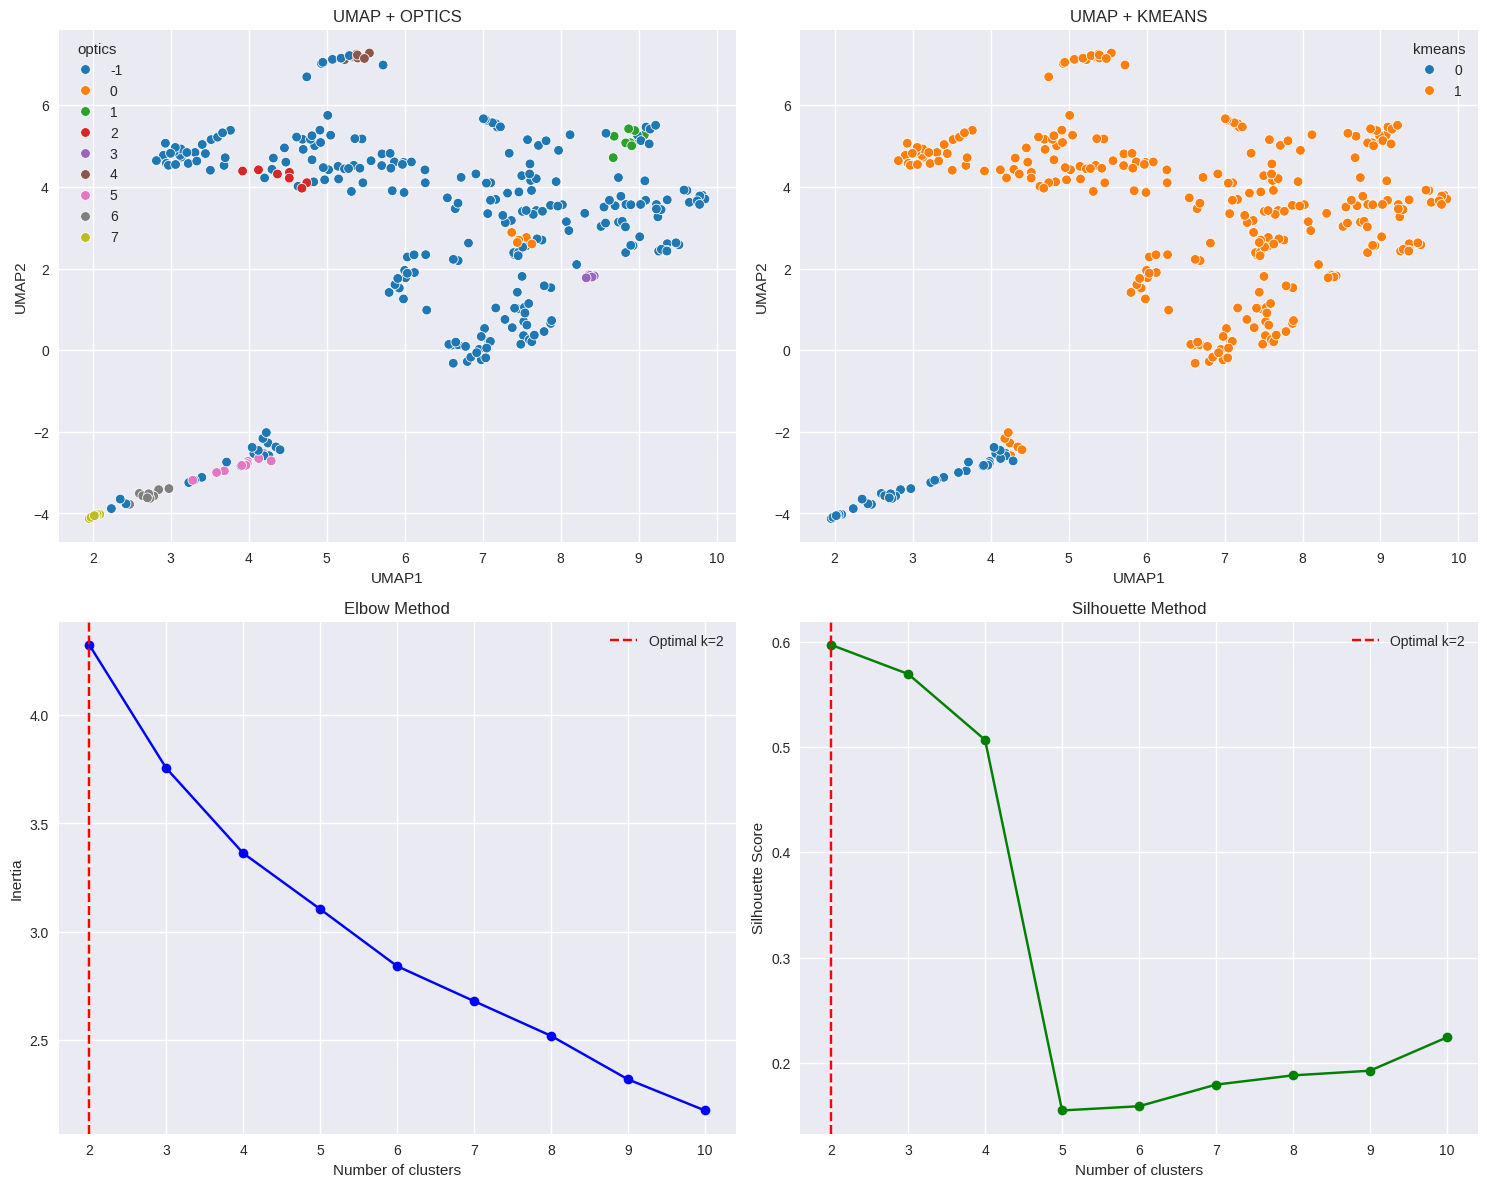


Clustering Results:
KMeans: 2 clusters, Silhouette score: 0.732
OPTICS: 8 clusters, Silhouette score: 0.825


In [141]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, OPTICS
from sklearn.metrics import silhouette_score
import umap
from scipy.spatial.distance import cdist


df = feat_df_de_corr.to_pandas().set_index("cp_feature").T  # Samples as rows
X = df

# UMAP embedding
embedding = umap.UMAP(random_state=42).fit_transform(X)

# Find optimal KMeans clusters using elbow method and silhouette score
def find_optimal_kmeans(X, max_k=10):
    inertias = []
    silhouette_scores = []
    K_range = range(2, max_k + 1)
    
    for k in K_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        kmeans.fit(X)
        inertias.append(kmeans.inertia_)
        silhouette_scores.append(silhouette_score(X, kmeans.labels_))
    
    # Elbow method
    elbow_k = 2
    for i in range(1, len(inertias)-1):
        if abs(inertias[i+1] - inertias[i]) < 0.1 * abs(inertias[i] - inertias[i-1]):
            elbow_k = i + 2
            break
    
    # Silhouette method
    silhouette_k = K_range[np.argmax(silhouette_scores)]
    
    # Choose the more conservative option
    optimal_k = min(elbow_k, silhouette_k)
    
    return optimal_k, inertias, silhouette_scores

# Find optimal OPTICS parameters
def find_optimal_optics(X):
    best_score = -1
    best_params = {'min_samples': 5, 'xi': 0.05}
    
    for min_samples in [3, 5, 7, 10]:
        for xi in [0.01, 0.05, 0.1]:
            optics = OPTICS(min_samples=min_samples, xi=xi)
            labels = optics.fit_predict(X)
            
            # Only evaluate if we have more than 1 cluster and not all noise
            if len(set(labels)) > 1 and -1 not in labels:
                score = silhouette_score(X, labels)
                if score > best_score:
                    best_score = score
                    best_params = {'min_samples': min_samples, 'xi': xi}
    
    return best_params

# Find optimal parameters
print("Finding optimal KMeans clusters...")
optimal_k, inertias, silhouette_scores = find_optimal_kmeans(X)
print(f"Optimal KMeans clusters: {optimal_k}")

print("Finding optimal OPTICS parameters...")
best_optics_params = find_optimal_optics(X)
print(f"Optimal OPTICS parameters: {best_optics_params}")

# Apply clustering with optimal parameters
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10).fit(X)
df['kmeans'] = kmeans.labels_

optics = OPTICS(**best_optics_params).fit(X)
df['optics'] = optics.labels_

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# UMAP plots
for i, method in enumerate(['optics', 'kmeans']):
    sns.scatterplot(x=embedding[:,0], y=embedding[:,1], hue=df[method], 
                   palette='tab10', ax=axes[0,i], legend='full')
    axes[0,i].set_title(f'UMAP + {method.upper()}')
    axes[0,i].set_xlabel('UMAP1')
    axes[0,i].set_ylabel('UMAP2')

# KMeans optimization plots
K_range = range(2, len(inertias) + 2)
axes[1,0].plot(K_range, inertias, 'bo-')
axes[1,0].axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k={optimal_k}')
axes[1,0].set_xlabel('Number of clusters')
axes[1,0].set_ylabel('Inertia')
axes[1,0].set_title('Elbow Method')
axes[1,0].legend()

axes[1,1].plot(K_range, silhouette_scores, 'go-')
axes[1,1].axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal k={optimal_k}')
axes[1,1].set_xlabel('Number of clusters')
axes[1,1].set_ylabel('Silhouette Score')
axes[1,1].set_title('Silhouette Method')
axes[1,1].legend()

plt.tight_layout()
plt.show()

# Print clustering results
print(f"\nClustering Results:")
print(f"KMeans: {optimal_k} clusters, Silhouette score: {silhouette_score(X, kmeans.labels_):.3f}")
print(f"OPTICS: {len(set(optics.labels_)) - (1 if -1 in optics.labels_ else 0)} clusters, Silhouette score: {silhouette_score(X, optics.labels_):.3f}")

### Mislocalization results

In [4]:
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")

    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])

## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()
misloc_alleles = (
    local_wtvar
    .select("allele_0")
    .to_series()
    .to_list()
)

misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        columns="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        ),
        (((pl.col("B7") == 1) & (pl.col("B8") != 1)) | ((pl.col("B7") != 1) & (pl.col("B8") == 1))).alias(
            "mislocalized_in_one_batch_only"
        ),
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

sig_misloc_alleles = misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]

In [5]:
misloc_binary

allele_0,Allele_set,mislocalized_batch7,mislocalized_batch8,mislocalized_both_batches,mislocalized_in_one_batch_only
str,str,i32,i32,bool,bool
"""SIX1_Val106Gly…","""A1P4""",0,0,false,false
"""DES_Pro433Thr""","""A1P1""",1,0,false,true
"""PMP22_His51Arg…","""A1P3""",0,0,false,false
"""KLHL3_Met78Val…","""A1P2""",0,0,false,false
"""PKP2_Asp26Asn""","""A1P3""",0,0,false,false
"""TUFM_Gly149Ser…","""A1P4""",0,0,false,false
"""CRADD_Gly128Ar…","""A1P1""",1,0,false,true
"""DES_Tyr331Asn""","""A1P1""",1,0,false,true
"""KRT86_Asn114As…","""A1P2""",1,0,false,true


In [6]:
feat_df_mean_pd = feat_df_mean.to_pandas()
feat_df_mean_pd["Allele"] = feat_df_mean_pd["Group2"].apply(lambda x: '_'.join(x.split("_")[1:]) if "_" in x else x)

## get the three classes of variants/alleles
feat_df_mean_pd_misloc_var = feat_df_mean_pd[feat_df_mean_pd["Allele"].isin(sig_misloc_alleles)]
feat_df_mean_pd_no_misloc_var = feat_df_mean_pd[~feat_df_mean_pd["Allele"].isin(sig_misloc_alleles)]
feat_df_mean_pd_ctrl_alleles = feat_df_mean_pd[feat_df_mean_pd["Variant_Type"]=="Control"][feat_df_mean_pd_misloc_var.columns]

## Important Features

### Visualize the top N (default n=10) most important features

In [17]:
def plot_top_n_important_feat(df, n=10, ax=None, title=""):
    # Calculate mean and standard deviation for each column
    column_stats = df[[col for col in df.columns if "GFP" in col]].agg(['mean', 'std']).T

    # Sort columns by the sum of mean and std in descending order
    sorted_columns = column_stats.sort_values(by=["mean"], ascending=False)
    sorted_columns = sorted_columns.head(n)
    # display(sorted_columns)

    # Plot mean and std for each column
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    ax.barh(y=sorted_columns.index, width=sorted_columns["mean"], color='skyblue') ## yerr=sorted_columns["std"], capsize=5, edgecolor='black'
    ax.set_yticks(range(len(sorted_columns.index)))
    ax.set_yticklabels(sorted_columns.index, rotation=0, fontsize=10)
    # ax.set_xlabel("Mean")
    ax.set_title(f"Features Importance Mean {title}")
    ax.axvline(x=0.01, color='r', linestyle='--')
    # plt.tight_layout()
    # plt.show()
    return sorted_columns

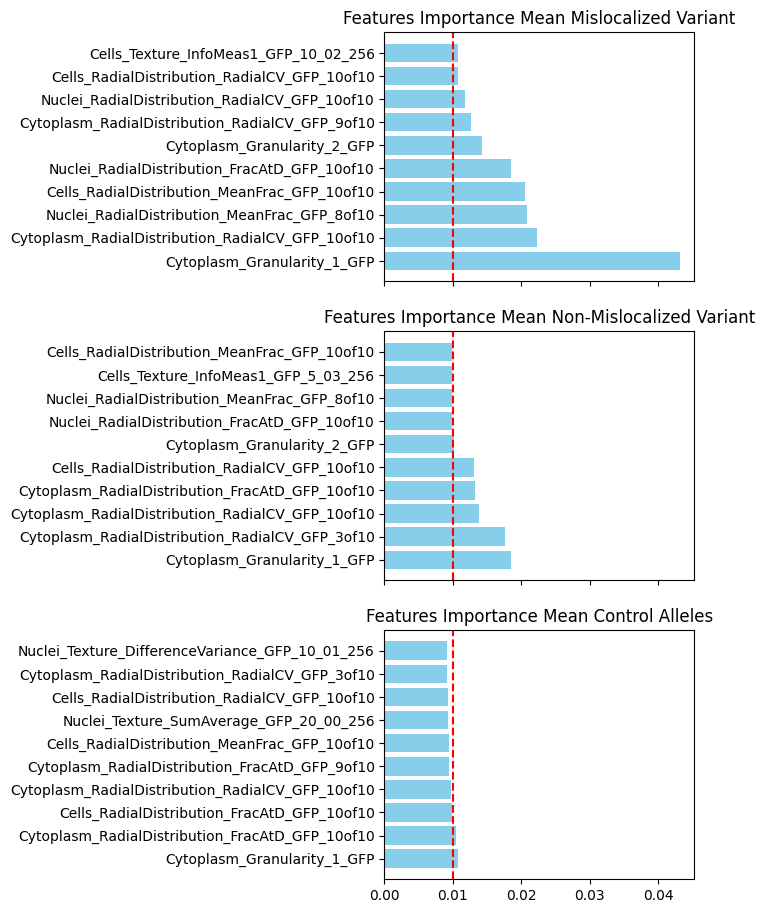

In [28]:
fig, axes = plt.subplots(3,1, figsize=(4, 11), sharex=True)
feat_import_misloc_var = plot_top_n_important_feat(feat_df_mean_pd_misloc_var, ax=axes[0], title="Mislocalized Variant")
feat_import_no_misloc_var = plot_top_n_important_feat(feat_df_mean_pd_no_misloc_var, ax=axes[1], title="Non-Mislocalized Variant")
feat_import_ctrl = plot_top_n_important_feat(feat_df_mean_pd_ctrl_alleles, ax=axes[2], title="Control Alleles")

In [30]:
feat_import_misloc_var.index #.sort_values()

Index(['Cytoplasm_Granularity_1_GFP',
       'Cytoplasm_RadialDistribution_RadialCV_GFP_10of10',
       'Nuclei_RadialDistribution_MeanFrac_GFP_8of10',
       'Cells_RadialDistribution_MeanFrac_GFP_10of10',
       'Nuclei_RadialDistribution_FracAtD_GFP_10of10',
       'Cytoplasm_Granularity_2_GFP',
       'Cytoplasm_RadialDistribution_RadialCV_GFP_9of10',
       'Nuclei_RadialDistribution_RadialCV_GFP_10of10',
       'Cells_RadialDistribution_RadialCV_GFP_10of10',
       'Cells_Texture_InfoMeas1_GFP_10_02_256'],
      dtype='object')

In [23]:
print("\n".join(sorted(set(feat_import_misloc_var.index.sort_values()).intersection(set(feat_import_no_misloc_var.index.sort_values())))))

Cells_RadialDistribution_MeanFrac_GFP_10of10
Cells_RadialDistribution_RadialCV_GFP_10of10
Cytoplasm_Granularity_1_GFP
Cytoplasm_Granularity_2_GFP
Cytoplasm_RadialDistribution_RadialCV_GFP_10of10
Nuclei_RadialDistribution_FracAtD_GFP_10of10
Nuclei_RadialDistribution_MeanFrac_GFP_8of10


In Cell Painting assays analyzed with CellProfiler, the feature called Cytoplasm_Granularity refers to the texture of the staining pattern within the cytoplasm, specifically measuring how “grainy” or “speckled” the signal is at different spatial scales.

Here’s a breakdown:

__What it Measures:__

* Granularity is a texture feature that captures the size and frequency of bright spots (or granules) in the image at multiple spatial scales.

* It’s based on morphological operations (often using granulometry) to assess how much image content (signal) is removed by a series of opening operations with structuring elements of increasing sizes.

* High granularity indicates numerous small, bright objects in the cytoplasm (e.g., vesicles, organelles).

* Low granularity implies a more uniform or diffuse staining pattern.

__How It Works in CellProfiler:__

* For each cytoplasm region, CellProfiler computes how much of the signal is lost when applying filters that remove structures below certain sizes.

* The result is a series of granularity features, each corresponding to a different scale (e.g., Cytoplasm_Granularity_1, Cytoplasm_Granularity_2, …).

* These scales correspond to different object sizes: smaller numbers = finer textures; larger numbers = coarser granules.

__In Cell Painting:__

* Different dyes highlight organelles like mitochondria, endoplasmic reticulum, Golgi, etc.

* Cytoplasm_Granularity can reflect changes in organelle morphology or distribution due to chemical or genetic perturbations.

* It’s used as a phenotypic descriptor in high-content screening and profiling.

## DR based on feature importance

### All variants and alleles

/tmp/ipykernel_183613/3239728625.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feat_df_mean_pd_misloc_var.loc[:,"Mislocalized"] = "2_Mislocalized"
/tmp/ipykernel_183613/3239728625.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feat_df_mean_pd_no_misloc_var.loc[:,"Mislocalized"] = "1_Non-Mislocalized"


Text(0.5, 0.97, 'PCA and UMAP of All Variants')

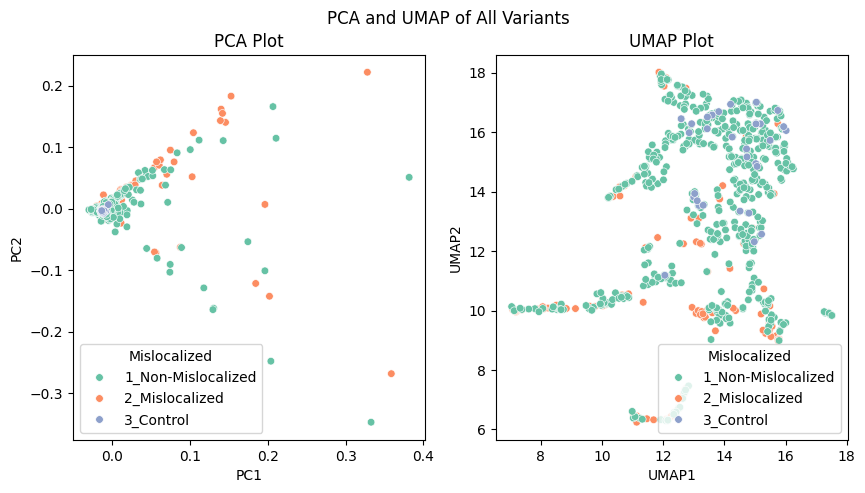

In [34]:
set2_palette = sns.color_palette("Set2", n_colors=3)

feat_df_mean_pd_misloc_var.loc[:,"Mislocalized"] = "2_Mislocalized"
feat_df_mean_pd_no_misloc_var.loc[:,"Mislocalized"] = "1_Non-Mislocalized"
feat_df_mean_pd_ctrl_alleles.loc[:,"Mislocalized"] = "3_Control"

feat_df_mean_pd_misloc_var_ctrl = pd.concat([feat_df_mean_pd_misloc_var, feat_df_mean_pd_no_misloc_var, feat_df_mean_pd_ctrl_alleles], ignore_index=True)
# display(feat_df_mean_pd_misloc_var_ctrl)

## Select the features based on the top n important features
numeric_cols = feat_df_mean_pd_misloc_var_ctrl.loc[:,feat_import_misloc_var.index]

# Standardize the features before PCA
# scaler = StandardScaler()
# numeric_cols = pd.DataFrame(scaler.fit_transform(numeric_cols), columns=numeric_cols.columns)

variant_type = feat_df_mean_pd_misloc_var_ctrl["Mislocalized"]
group2_labels = feat_df_mean_pd_misloc_var_ctrl["Allele"]

# Perform PCA
pca = PCA(n_components=10)
pca_result = pca.fit_transform(numeric_cols)

# Plot PCA
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=variant_type, palette=set2_palette, s=30, ax=ax[0], hue_order=["1_Non-Mislocalized", "2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     # if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#     texts.append(ax[0].text(pca_result[i, 0], pca_result[i, 1], label, 
#                     fontsize=8, fontweight='bold', color='black'))
# # print(texts)
# adjust_text(texts, expand_points=(4, 4), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 
ax[0].set_title("PCA Plot")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(numeric_cols)

sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette=set2_palette, s=30, ax=ax[1], hue_order=["1_Non-Mislocalized", "2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     texts.append(ax[1].text(umap_result[i, 0], umap_result[i, 1], label, 
#                     fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 
ax[1].set_title("UMAP Plot")
ax[1].set_xlabel("UMAP1")
ax[1].set_ylabel("UMAP2")
plt.suptitle("PCA and UMAP of All Variants", y=.97)

In [ ]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=numeric_cols.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

### Compare mislocalized variants vs control alleles

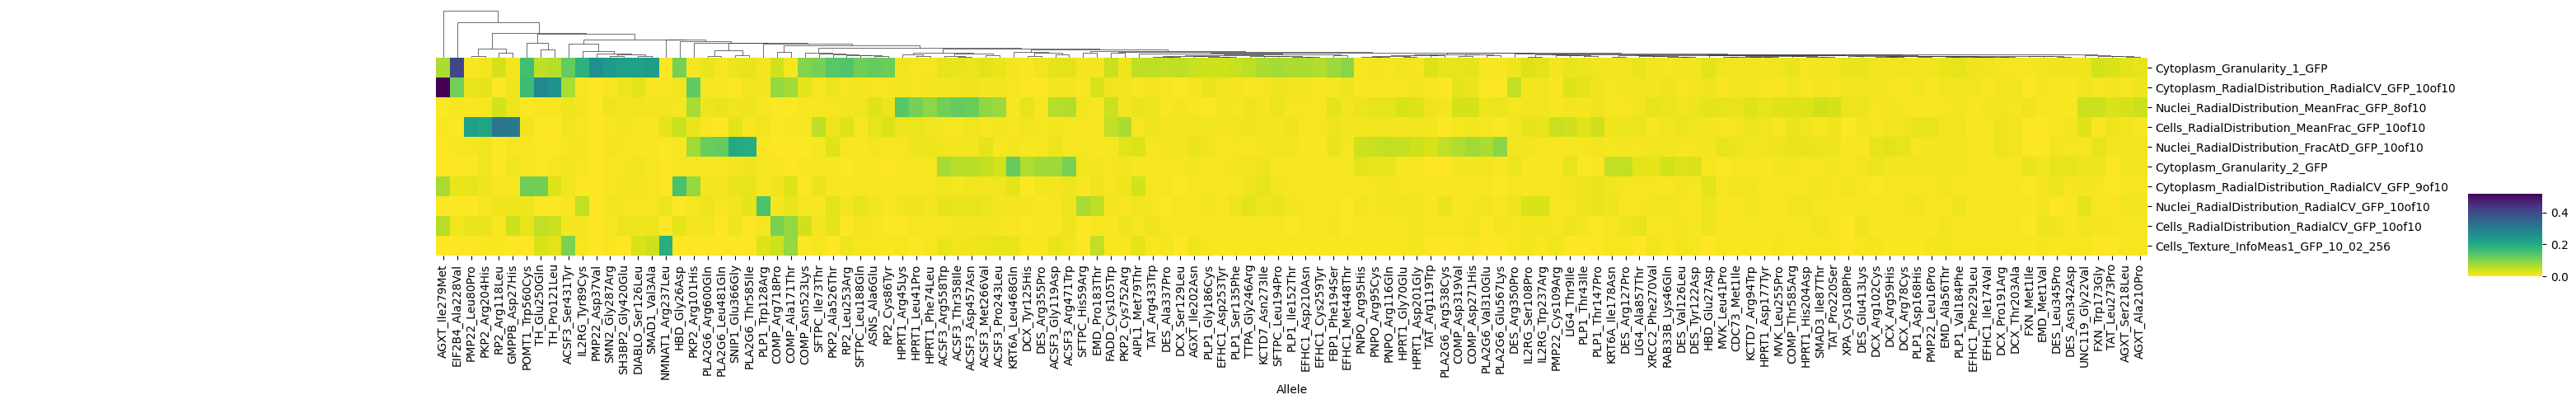

In [33]:
sns.clustermap(feat_df_mean_pd_misloc_var[["Allele"]+feat_import_misloc_var.index.to_list()].set_index("Allele").T,
xticklabels=1, cbar_pos=(1., .32, .03, .2),
figsize=(30, 5), cmap="viridis_r", row_cluster=False, col_cluster=True)

,Group1,Group2,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_10_03_256,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cytoplasm_Texture_Correlation_GFP_20_03_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,...,Nuclei_Texture_DifferenceVariance_GFP_10_01_256,Cells_RadialDistribution_MeanFrac_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_InfoMeas1_GFP_10_02_256,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cells_Texture_InfoMeas1_GFP_5_01_256,Variant_Type,Allele,Mislocalized
0,EMD,EMD_EMD_Pro183Thr,0.006859,0.004087,0.007973,0.007753,0.005034,0.003104,0.007272,0.005756,...,0.010440,0.002906,0.052236,0.009291,0.025962,0.006457,0.001657,Allele,EMD_Pro183Thr,2_Mislocalized
1,DES,DES_DES_Asn342Asp,0.005487,0.006709,0.009803,0.005560,0.005161,0.005570,0.007082,0.007117,...,0.007889,0.005362,0.004734,0.003920,0.005899,0.004835,0.007237,Allele,DES_Asn342Asp,2_Mislocalized
2,DES,DES_DES_Arg355Pro,0.003320,0.003643,0.006497,0.004074,0.005004,0.003445,0.005013,0.004360,...,0.007560,0.004442,0.006028,0.004818,0.005328,0.005034,0.014418,Allele,DES_Arg355Pro,2_Mislocalized
3,COMP,COMP_COMP_Arg718Pro,0.001389,0.001449,0.002647,0.001557,0.002224,0.000660,0.003011,0.004193,...,0.001399,0.002649,0.006079,0.002232,0.010591,0.002660,0.000384,Allele,COMP_Arg718Pro,2_Mislocalized
4,TH,TH_TH_Glu250Gln,0.006133,0.001535,0.002530,0.003425,0.002642,0.002150,0.004486,0.003303,...,0.000814,0.004787,0.003464,0.000251,0.044228,0.003571,0.002010,Allele,TH_Glu250Gln,2_Mislocalized
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,SLIRP,H17_H18,0.007805,0.008176,0.008424,0.007974,0.008015,0.007345,0.008492,0.008632,...,0.010735,0.007864,0.007240,0.008082,0.009076,0.008053,0.009339,Control,H18,3_Control
149,RHEB,I16_J15,0.008941,0.008731,0.010186,0.007145,0.008605,0.007804,0.008014,0.007195,...,0.009074,0.007624,0.007737,0.007523,0.008133,0.007900,0.007748,Control,J15,3_Control
150,SLIRP,G18_H18,0.008206,0.008745,0.006969,0.007454,0.007968,0.007573,0.008712,0.007812,...,0.009192,0.007286,0.008889,0.007584,0.008622,0.007738,0.009597,Control,H18,3_Control
151,SLIRP,G17_H18,0.008297,0.007452,0.008432,0.008121,0.007378,0.008754,0.008102,0.007980,...,0.008836,0.008020,0.009212,0.008499,0.008764,0.008432,0.008883,Control,H18,3_Control


Text(0.5, 0.97, 'PCA and UMAP of Mislocalzed vs Control Variants')

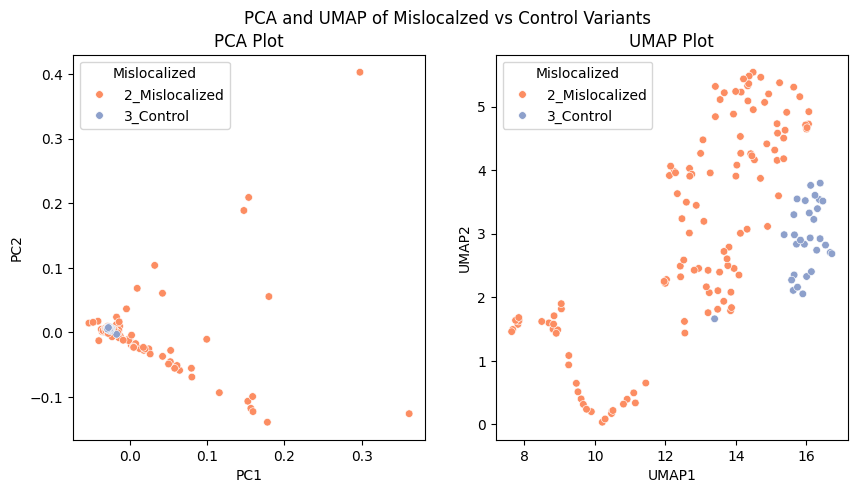

In [10]:
feat_df_mean_pd_misloc_var_ctrl = pd.concat([feat_df_mean_pd_misloc_var, feat_df_mean_pd_ctrl_alleles], ignore_index=True)
display(feat_df_mean_pd_misloc_var_ctrl)

## Select the features based on the top n important features
numeric_cols = feat_df_mean_pd_misloc_var_ctrl.loc[:,feat_import_misloc_var.index]

# Standardize the features before PCA
# scaler = StandardScaler()
# numeric_cols = pd.DataFrame(scaler.fit_transform(numeric_cols), columns=numeric_cols.columns)

variant_type = feat_df_mean_pd_misloc_var_ctrl["Mislocalized"]
group2_labels = feat_df_mean_pd_misloc_var_ctrl["Allele"]

# Perform PCA
pca = PCA(n_components=10)
pca_result = pca.fit_transform(numeric_cols)

# Plot PCA
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=variant_type, palette=set2_palette[1:], s=30, ax=ax[0], hue_order=["2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     # if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
#     texts.append(ax[0].text(pca_result[i, 0], pca_result[i, 1], label, 
#                     fontsize=8, fontweight='bold', color='black'))
# # print(texts)
# adjust_text(texts, expand_points=(4, 4), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 
ax[0].set_title("PCA Plot")
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(numeric_cols)

sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette=set2_palette[1:], s=30, ax=ax[1], hue_order=["2_Mislocalized", "3_Control"])
# texts = []
# for i, label in enumerate(group2_labels):
#     texts.append(ax[1].text(umap_result[i, 0], umap_result[i, 1], label, 
#                     fontsize=6, fontweight='bold', color='black'))
# adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1]) ## 
ax[1].set_title("UMAP Plot")
ax[1].set_xlabel("UMAP1")
ax[1].set_ylabel("UMAP2")
plt.suptitle("PCA and UMAP of Mislocalzed vs Control Variants", y=.97)

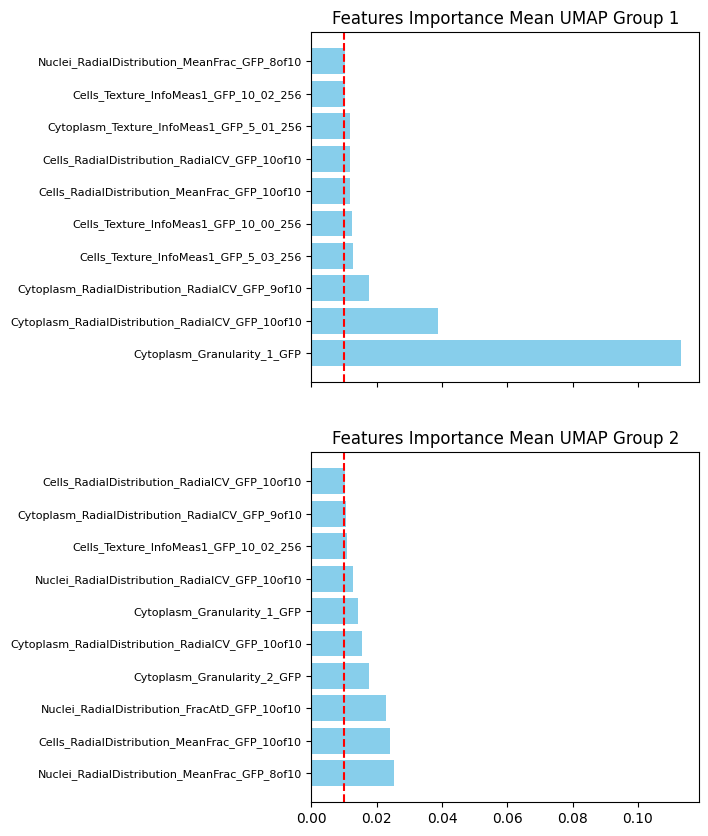

In [11]:
umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Variant_Type"] = variant_type.to_list()
umap_df["Group2"] = group2_labels.to_list()
umap_df["Group1"] = feat_df_mean_pd_misloc_var_ctrl["Group1"].to_list()
umap_group1 = umap_df[umap_df["UMAP1"]<12]["Group2"].unique()

fig, axes = plt.subplots(2, 1, figsize=(5, 10), sharex=True)
umap_group1_fi = plot_top_n_important_feat(feat_df_mean_pd_misloc_var[feat_df_mean_pd_misloc_var["Allele"].isin(umap_group1)], 
n=10, ax=axes[0], title="UMAP Group 1")
# display(umap_group1_fi)
umap_group2_fi = plot_top_n_important_feat(feat_df_mean_pd_misloc_var[~feat_df_mean_pd_misloc_var["Allele"].isin(umap_group1)], 
n=10, ax=axes[1], title="UMAP Group 2")

In [15]:
umap_group1 #.shape

array(['IL2RG_Tyr89Cys', 'KCTD7_Asn273Ile', 'AGXT_Ile279Met',
       'ASNS_Ala6Glu', 'ACSF3_Ser431Tyr', 'HBD_Gly26Asp',
       'SFTPC_Leu188Gln', 'SH3BP2_Gly420Glu', 'DIABLO_Ser126Leu',
       'PLP1_Ser135Phe', 'DES_Ala337Pro', 'SFTPC_Leu194Pro',
       'EIF2B4_Ala228Val', 'TH_Pro121Leu', 'EFHC1_Asp253Tyr',
       'FBP1_Phe194Ser', 'POMT1_Trp560Cys', 'AIPL1_Met79Thr',
       'EFHC1_Cys259Tyr', 'AGXT_Ile202Asn', 'SMAD1_Val3Ala',
       'RP2_Cys86Tyr', 'EFHC1_Met448Thr', 'SFTPC_Ile73Thr',
       'SMN2_Gly287Arg', 'EFHC1_Asp210Asn', 'PKP2_Ala526Thr',
       'RP2_Leu253Arg', 'PLP1_Ile152Thr', 'PMP22_Asp37Val',
       'PLP1_Gly186Cys', 'TAT_Arg433Trp', 'TTPA_Gly246Arg',
       'DCX_Ser129Leu', 'COMP_Asn523Lys', 'FXN_Trp173Gly'], dtype=object)

In [13]:
umap_df["Gene"] = umap_df["Group2"].apply(lambda x: x.split("_")[0])
umap_df[umap_df["Group2"].isin(umap_group1)].groupby("Gene").count().sort_values("Group2", ascending=False)

,UMAP1,UMAP2,Variant_Type,Group2,Group1
Gene,,,,,
EFHC1,4,4,4,4,4
SFTPC,3,3,3,3,3
PLP1,3,3,3,3,3
AGXT,2,2,2,2,2
RP2,2,2,2,2,2
AIPL1,1,1,1,1,1
COMP,1,1,1,1,1
DES,1,1,1,1,1
ASNS,1,1,1,1,1


### Key features contributing to PC variantion

In [14]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=numeric_cols.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Cytoplasm_Granularity_1_GFP,0.833312,-0.545650,0.081416,-0.001155,0.022653,0.026489,0.001170,0.002797,0.001793,-0.001020
Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,0.539058,0.830559,0.043520,-0.131805,-0.001588,0.012446,0.008246,-0.006839,0.006931,0.001015
Cells_RadialDistribution_RadialCV_GFP_10of10,0.063789,0.110814,0.040902,0.976084,0.156414,0.059746,0.019961,0.004737,-0.026841,0.007907
Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,-0.009713,-0.001079,0.006670,-0.021699,-0.041001,0.414587,-0.362953,-0.646897,-0.522300,-0.053088
Cells_RadialDistribution_FracAtD_GFP_10of10,-0.011601,0.005264,-0.007788,-0.040170,-0.017044,0.463965,-0.049490,0.729123,-0.485963,-0.111266
Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,-0.013295,-0.001892,-0.010641,-0.017413,-0.017469,0.438376,-0.157972,0.046617,0.318504,0.823621
Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,-0.014011,0.001207,-0.009066,0.007065,-0.057277,0.490362,-0.251308,0.000841,0.623248,-0.551670
Nuclei_Texture_SumAverage_GFP_20_00_256,-0.021284,-0.010063,-0.007843,-0.048636,0.057334,0.418318,0.877222,-0.218118,-0.005468,-0.040219
Nuclei_Texture_DifferenceVariance_GFP_10_01_256,-0.028533,-0.003061,-0.012290,-0.154030,0.982934,0.027173,-0.087818,-0.001604,0.016288,-0.020550
Cells_RadialDistribution_MeanFrac_GFP_10of10,-0.095237,0.003688,0.994631,-0.036855,0.003813,0.008476,0.002620,0.008689,0.009598,0.002411


## Hierarchical Clusterings

In [27]:
feat_df_mean_pd_misloc_var 

,Group1,Group2,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_10_03_256,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cytoplasm_Texture_Correlation_GFP_20_03_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,...,Nuclei_Texture_Correlation_GFP_20_01_256,Nuclei_Texture_DifferenceVariance_GFP_10_01_256,Cells_RadialDistribution_MeanFrac_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_InfoMeas1_GFP_10_02_256,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cells_Texture_InfoMeas1_GFP_5_01_256,Variant_Type,Allele
2,TAT,TAT_TAT_Arg433Trp,0.003058,0.001500,0.012786,0.003118,0.005178,0.003393,0.004884,0.003661,...,0.003021,0.003518,0.003115,0.006703,0.002661,0.003115,0.005241,0.006494,Allele,TAT_Arg433Trp
11,PKP2,PKP2_PKP2_Arg101His,0.004641,0.002277,0.016615,0.006645,0.003805,0.003119,0.003998,0.003457,...,0.000529,0.003498,0.004954,0.006461,0.000561,0.002056,0.003305,0.012839,Allele,PKP2_Arg101His
13,ACSF3,ACSF3_ACSF3_Thr358Ile,0.003593,0.003442,0.004206,0.005665,0.013756,0.003360,0.002536,0.003795,...,0.003936,0.004999,0.005975,0.016949,0.002202,0.004947,0.004751,0.010666,Allele,ACSF3_Thr358Ile
14,ACSF3,ACSF3_ACSF3_Asp457Asn,0.004439,0.004198,0.012047,0.007927,0.006609,0.007283,0.006214,0.004954,...,0.004373,0.003245,0.006442,0.020113,0.002852,0.005805,0.002999,0.002957,Allele,ACSF3_Asp457Asn
22,DES,DES_DES_Leu345Pro,0.004458,0.004585,0.007309,0.007856,0.003501,0.005725,0.008935,0.004404,...,0.003839,0.008609,0.004737,0.003856,0.003844,0.010399,0.003749,0.028110,Allele,DES_Leu345Pro
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
637,ACSF3,ACSF3_ACSF3_Pro243Leu,0.002528,0.004011,0.011708,0.005743,0.007106,0.006757,0.004190,0.006715,...,0.002353,0.008567,0.006970,0.009627,0.001127,0.005048,0.006626,0.017887,Allele,ACSF3_Pro243Leu
643,HPRT1,HPRT1_HPRT1_Gly70Glu,0.006280,0.006666,0.008678,0.005211,0.008945,0.006422,0.005601,0.008520,...,0.009282,0.008783,0.009573,0.010289,0.006025,0.007429,0.007054,0.011114,Allele,HPRT1_Gly70Glu
654,PLA2G6,PLA2G6_PLA2G6_Val310Glu,0.002228,0.000598,0.006520,0.007346,0.004371,0.003413,0.001784,0.005958,...,0.000000,0.009410,0.005770,0.011909,0.000000,0.000158,0.003828,0.010162,Allele,PLA2G6_Val310Glu
659,PLA2G6,PLA2G6_PLA2G6_Thr585Ile,0.000000,0.000758,0.005051,0.004527,0.001770,0.000953,0.003793,0.006088,...,0.000547,0.000878,0.002076,0.020302,0.000768,0.000685,0.002178,0.000184,Allele,PLA2G6_Thr585Ile


In [40]:
feature_names = list(feat_import_misloc_var.index)
df = feat_df_mean_pd_misloc_var[["Group1", "Group2"] + feature_names].copy()

In [41]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

silhouette_scores = []
cluster_range = range(2, 10)  # Trying clusters from 2 to 9

for k in cluster_range:
    clustering = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = clustering.fit_predict(df[feature_names])
    score = silhouette_score(df[feature_names], labels)
    silhouette_scores.append(score)
    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Select the number of clusters that has the highest silhouette score
optimal_clusters = cluster_range[np.argmax(silhouette_scores)]
print(f"Optimal number of clusters determined: {optimal_clusters}")

Clusters: 2, Silhouette Score: 0.5992
Clusters: 3, Silhouette Score: 0.5794
Clusters: 4, Silhouette Score: 0.6153
Clusters: 5, Silhouette Score: 0.2990
Clusters: 6, Silhouette Score: 0.3305
Clusters: 7, Silhouette Score: 0.3592
Clusters: 8, Silhouette Score: 0.3446
Clusters: 9, Silhouette Score: 0.3730
Optimal number of clusters determined: 4


In [50]:
# ----------------------------
# 3. Perform Hierarchical Clustering with the Optimal Cluster Count
# ----------------------------
agg_model = AgglomerativeClustering(n_clusters=5, linkage='ward')
df.loc[:,'cluster'] = agg_model.fit_predict(df[feature_names])

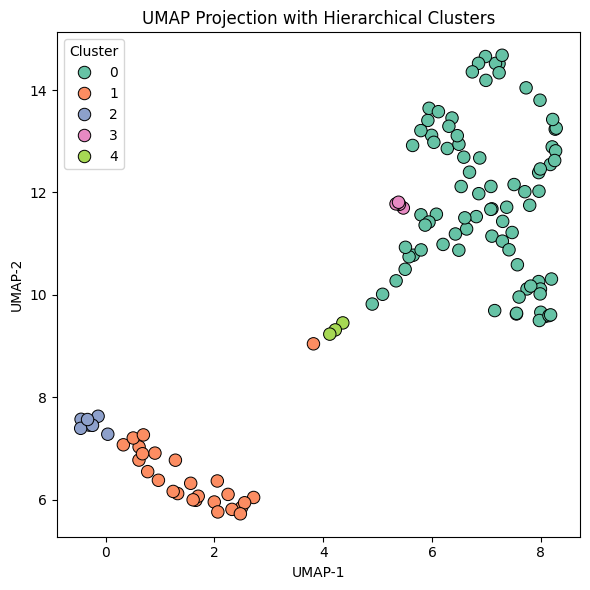

In [58]:
# ----------------------------
# 4. Compute UMAP Projection and Plot the Clusters
# ----------------------------
umap_reducer = umap.UMAP(random_state=42)
embedding = umap_reducer.fit_transform(df[feature_names])
df['UMAP-1'] = embedding[:, 0]
df['UMAP-2'] = embedding[:, 1]

plt.figure(figsize=(6, 6))
sns.scatterplot(x='UMAP-1', y='UMAP-2', hue='cluster', 
                palette='Set2', data=df, s=80, edgecolor='k')
plt.title("UMAP Projection with Hierarchical Clusters")
plt.xlabel("UMAP-1")
plt.ylabel("UMAP-2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

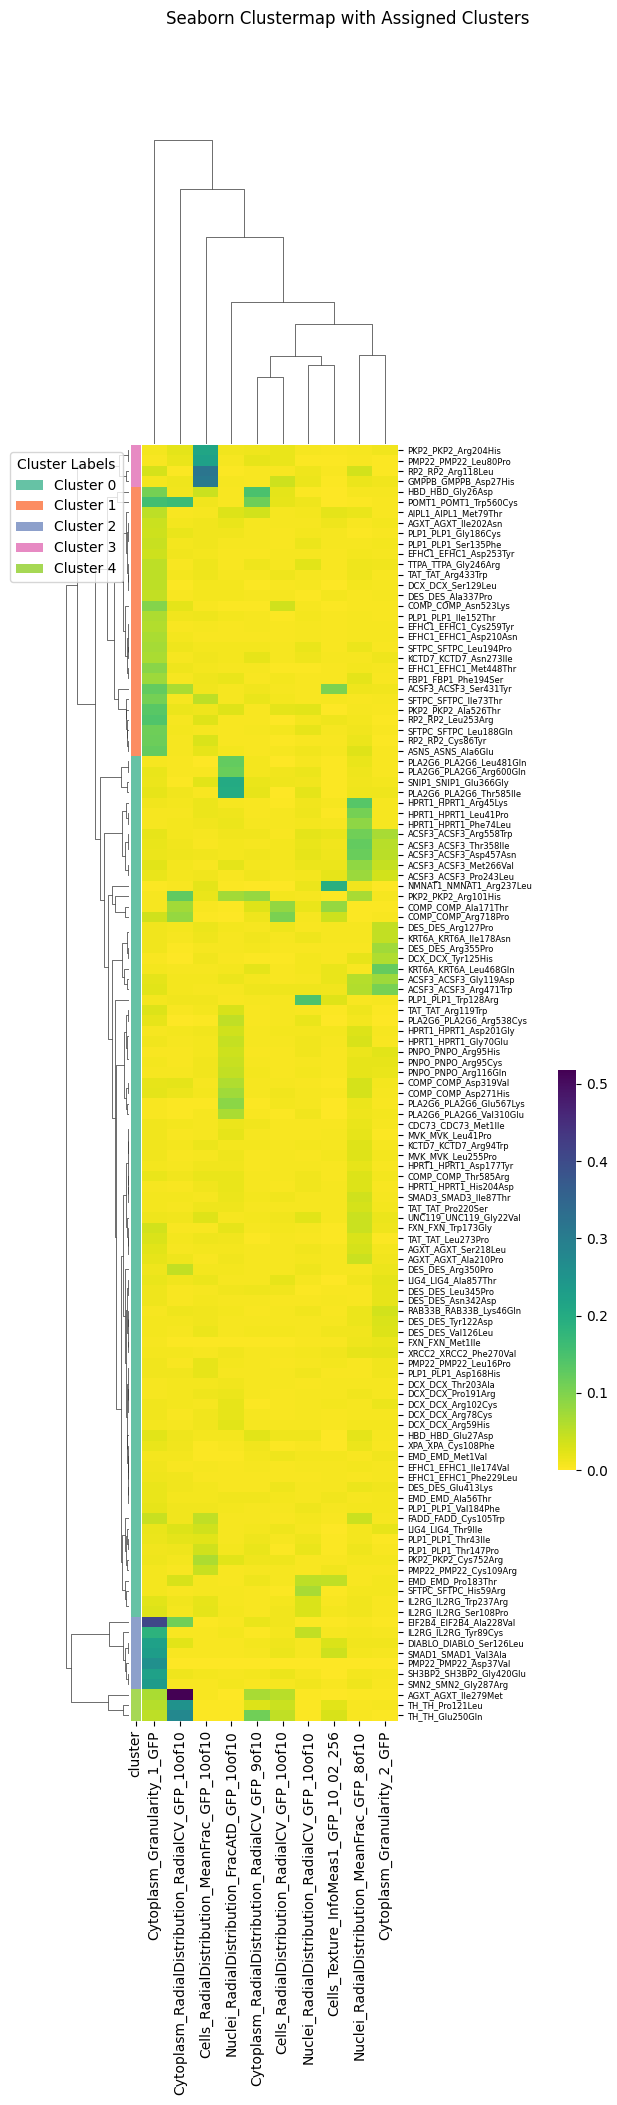

In [77]:
# df = df.set_index("Group2")
unique_clusters = np.sort(df['cluster'].unique())
palette = sns.color_palette("Set2", len(unique_clusters))
lut = dict(zip(unique_clusters, palette))
row_colors = df['cluster'].map(lut)

# Create the clustermap. We use only the original features.
# The row_colors argument is used to annotate the rows based on our clusters.
g = sns.clustermap(df[feature_names],
                   row_colors=row_colors,
                   metric="euclidean",
                   method="ward",
                   cmap="viridis_r",
                   cbar_pos=(.85, .32, .03, .2),
                   figsize=(6, 20),
                   yticklabels=df.index)

# Optionally, add a legend for the row_colors
for label in unique_clusters:
    g.ax_row_dendrogram.bar(1, 0, color=lut[label],
                            label=f'Cluster {label}', linewidth=0)
g.ax_row_dendrogram.legend(loc="upper right", ncol=1, title="Cluster Labels")
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0, fontsize=6)
plt.setp(g.ax_heatmap.set_ylabel(""), rotation=0, fontsize=6)
plt.suptitle("Seaborn Clustermap with Assigned Clusters", y=1.05)
plt.show()